# CENTAUR admin analysis (area in drought)

In [16]:
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib.colors import BoundaryNorm
from matplotlib.ticker import (MultipleLocator, AutoMinorLocator)
from matplotlib.colors import LinearSegmentedColormap
import matplotlib.dates as mdates
from matplotlib.dates import DateFormatter
from mpl_toolkits.basemap import Basemap
from mpl_toolkits.basemap import shiftgrid
import numpy as np
import os
import datetime as dt
import pandas as pd
import geopandas as gpd
import shapely
import sys
import calendar
import netCDF4 as nc4
import xarray as xr
#xr.set_options(display_expand_attrs=False)
from dateutil import relativedelta
from datetime import timedelta
import fiona
from shapely.geometry import shape
import pprint
import regionmask

In [17]:
from helpers.geodata import calculate_gridarea

## ECMWF data / WFS-ID-1

In [18]:
ipath_ecmwf = "/ec/vol/centaur/nejk/drought_monitor"

In [26]:
## Settings
syyyy = 1991
eyyyy = 2023
severity_list = ['moderate','severe','extreme','any']
quant_list    = ['min','median','max']

#### Landmask

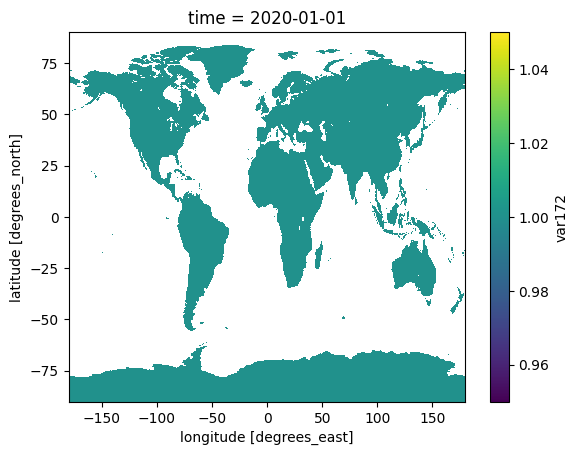

In [20]:
# read landmasks
varname       = "var172"
# binary mask (0/1)
ifile_name    = "landmask_era5_global.nc"
ifile         = os.path.join("/home/nejk/code/drought_on_demand/masks", ifile_name)
landmask_ecm = xr.open_dataset(ifile)[varname]
landmask_ecm = landmask_ecm.where( landmask_ecm.values == 1 )
landmask_ecm.plot()

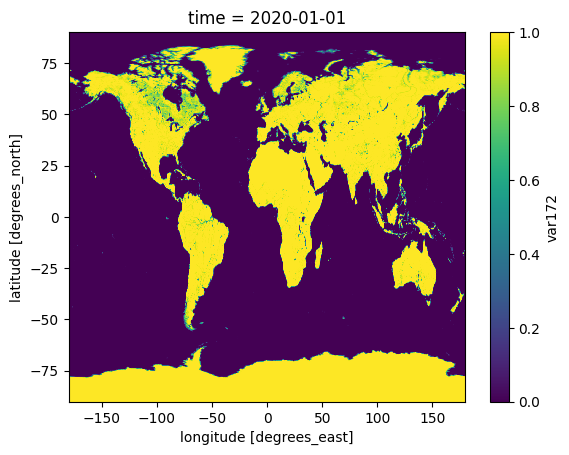

In [21]:
# fraction mask (0-1)
ifile_name     = "landmask_era5_global_frac.nc"
ifile          = os.path.join("/home/nejk/code/drought_on_demand/masks", ifile_name)
landmaskfr_ecm = xr.open_dataset(ifile)[varname]
landmaskfr_ecm = landmaskfr_ecm.where( landmaskfr_ecm.values >= 0 )
landmaskfr_ecm.plot()

#### Grid area (incl. land fraction)

(721, 1440, 1)


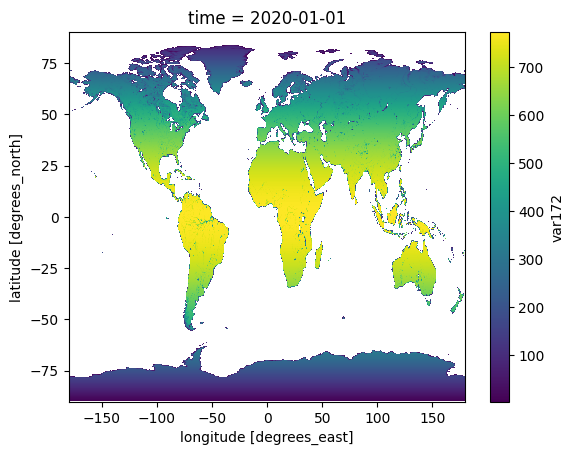

In [22]:
area_2d_ecm = calculate_gridarea(landmask_ecm.lat, res=abs(landmask_ecm.lat[1]-landmask_ecm.lat[0]), nlon=len(landmask_ecm.lon))*landmask_ecm[0,:,:]
area_2d_ecm = xr.DataArray(area_2d_ecm, coords={'lat': landmask_ecm.lat,'lon': landmask_ecm.lon}, dims=["lat", "lon"])
#area_2d_ecm.plot()

# adjust using land fraction
area_2d_adj_ecm = area_2d_ecm * landmaskfr_ecm
area_2d_adj_ecm.plot()
#(area_2d_ecm - area_2d_adj_ecm).plot()
print(area_2d_adj_ecm.shape)

## Mozambique

### ADMIN1 - DATA

#### Read ADMIN shp and get all ADMIN IDs 

In [30]:
shppath="/ec/vol/centaur/wfs_data/0_FEWSNET_ADMIN/ColdCases"
adminshp=f"{shppath}/MZ_Admin1_2021.shp"

# Open the shapefile with gpd
shapefile=gpd.read_file(adminshp) 
#print(shapefile)
print(shapefile['ADMIN1'])
print(shapefile['FNID'])
admin1_df = pd.DataFrame({'fnid': shapefile['FNID'], 'admin1': shapefile['ADMIN1']})
print(admin1_df)

fnids = shapefile['FNID']
fnids[0].lower()

0     Cabo Delgado
1             Gaza
2        Inhambane
3           Manica
4           Maputo
5      Maputo City
6          Nampula
7           Niassa
8           Sofala
9             Tete
10        Zambezia
Name: ADMIN1, dtype: object
0     MZ2021A101
1     MZ2021A102
2     MZ2021A103
3     MZ2021A104
4     MZ2021A105
5     MZ2021A106
6     MZ2021A107
7     MZ2021A108
8     MZ2021A109
9     MZ2021A110
10    MZ2021A111
Name: FNID, dtype: object
          fnid        admin1
0   MZ2021A101  Cabo Delgado
1   MZ2021A102          Gaza
2   MZ2021A103     Inhambane
3   MZ2021A104        Manica
4   MZ2021A105        Maputo
5   MZ2021A106   Maputo City
6   MZ2021A107       Nampula
7   MZ2021A108        Niassa
8   MZ2021A109        Sofala
9   MZ2021A110          Tete
10  MZ2021A111      Zambezia


'mz2021a101'

#### Test masking for each ADMIN

MZ2021A101
103
MZ2021A102
108
MZ2021A103
98
MZ2021A104
87
MZ2021A105
31
MZ2021A106
1
MZ2021A107
108
MZ2021A108
169
MZ2021A109
94
MZ2021A110
136
MZ2021A111
138


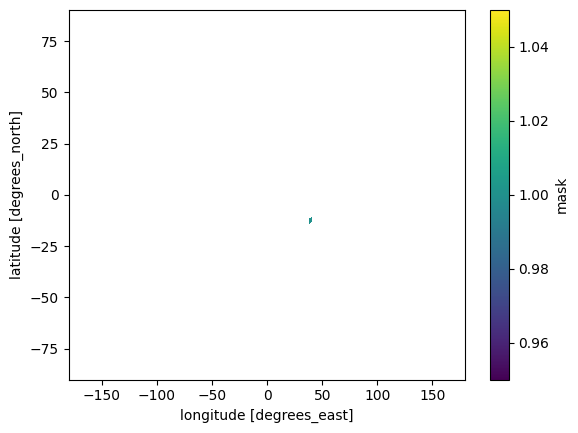

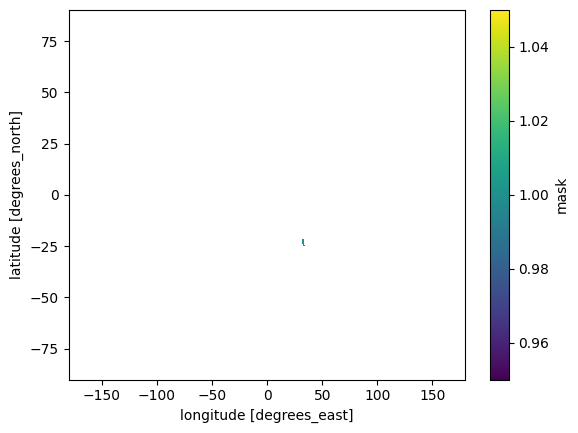

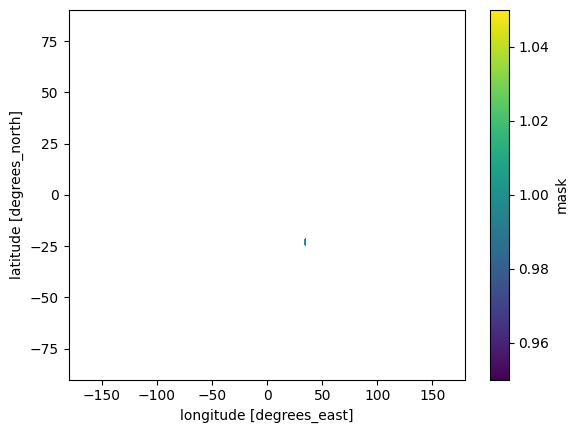

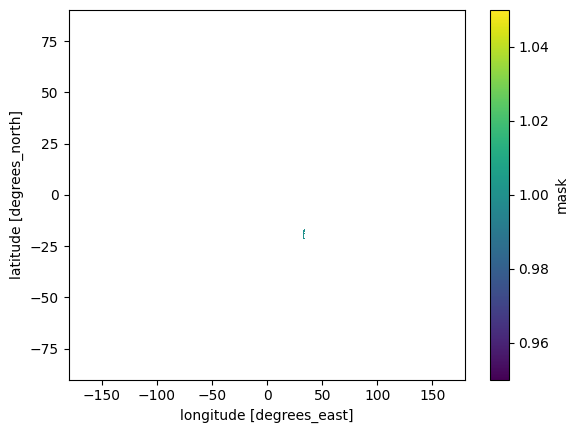

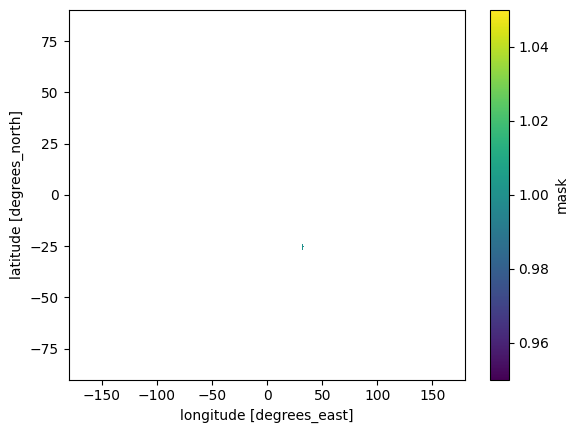

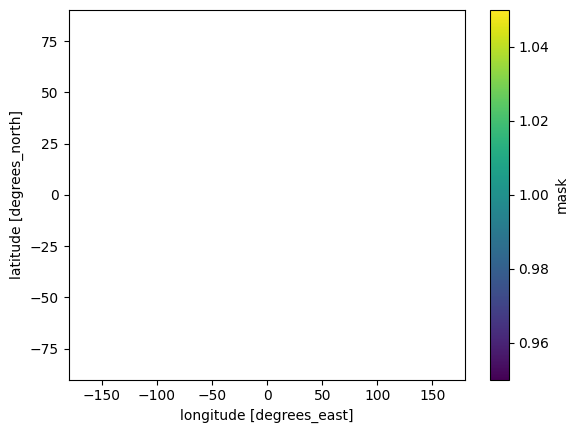

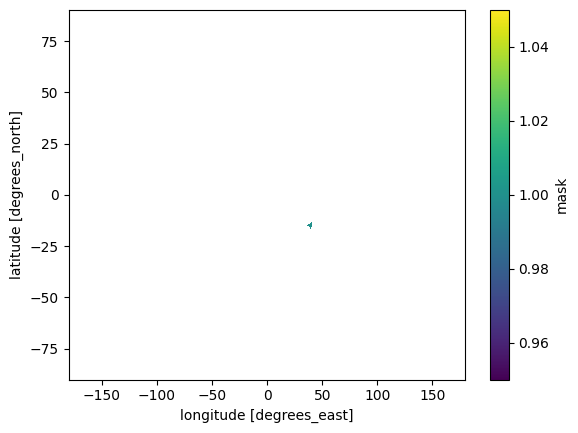

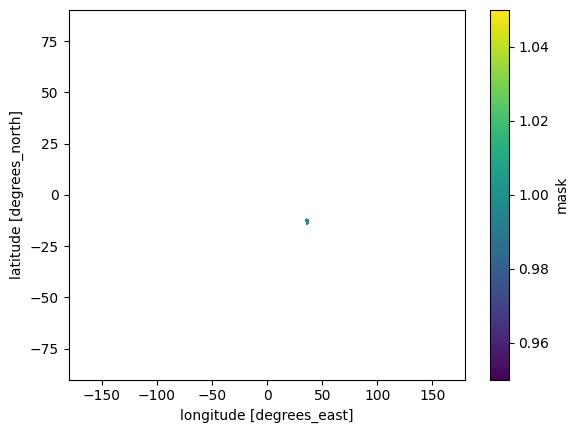

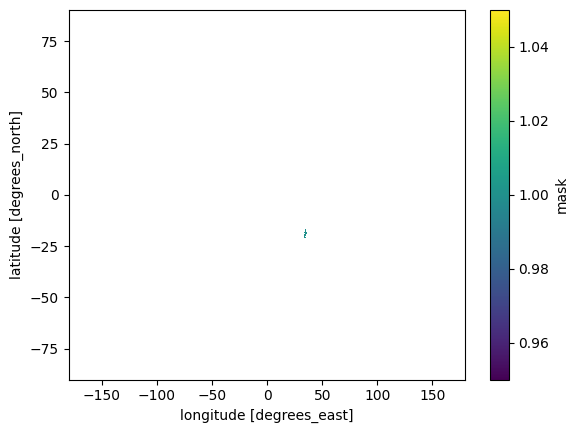

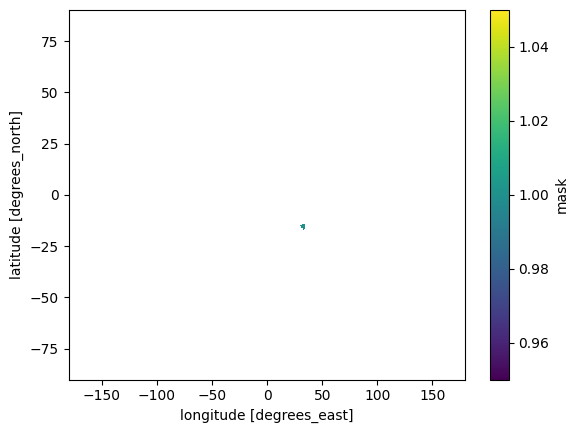

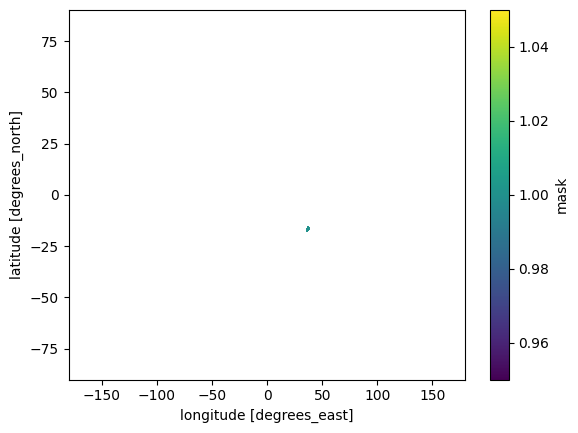

In [9]:
# Check all individual admin1 FNIDs
for ifnid in shapefile['FNID']:
    print(ifnid)
    fnshp = shapefile.loc[ (shapefile.FNID.isin([ifnid])), 'geometry' ]
    fnshp = fnshp.to_crs('epsg:4326')
    #plt.figure()
    #fnshp.plot()
    
    #print(fnshp.index.values) # this increases with the number of polygons in the original shapefile 
    adminmask = regionmask.mask_geopandas(fnshp, landmask_ecm.lon, landmask_ecm.lat)
    adminmask = xr.where(adminmask == fnshp.index.values, 1, np.nan) # otherwise this increases and the mask has values 0-len(fnids)
    
    #print(adminmask.shape)

    # Check number of pixels in adminmask
    print(int(adminmask.sum().values))

    # Test plot
    plt.figure()
    adminmask.plot()

# all admin1 FNIDs together
#fnshpa = shapefile.loc[ (shapefile.FNID.isin(shapefile['FNID'])), 'geometry' ] 
#fnshpa.plot()

#### Estimate area in drought for each ADMIN 

In [ ]:
for ifnid in fnids[0:1]:
    
    print(ifnid)
    fnshp = shapefile.loc[ (shapefile.FNID.isin([ifnid])), 'geometry' ]
    fnshp = fnshp.to_crs('epsg:4326')
    #plt.figure()
    #fnshp.plot()
    
    print(fnshp.index.values)
    adminmask = regionmask.mask_geopandas(fnshp, landmask_ecm.lon, landmask_ecm.lat)
    adminmask = xr.where(adminmask == fnshp.index.values, 1, np.nan) # otherwise this increases and the mask has values 0-len(fnids)
    print(adminmask.shape)
    plt.figure()
    adminmask.plot()
    
    # calculate area in drought
    indicator="SPI"
    aid_spi_ecm = {}
    #for window in [1,3,6,12,24,36,48]:
    for window in [1]:
        
        print(f"Processing SPI-{window}")
        swindow=f"w{window}"
        aid_spi_ecm = {}
        #aid_spi_ecm[swindow] = {}
        
        for severity in severity_list:    
            ivar = f"{indicator}{window}_{severity}"
            aid_spi_ecm[ivar] = pd.Series()
    
        date_list_ecm = []
        #for iyyyy in range(syyyy, eyyyy+1):
        for iyyyy in range(1991, 1991+1):
            for imonth in range(1,13):
    
                idate = f"{iyyyy}-{str(imonth).zfill(2)}"
                date_list_ecm.append(f"{iyyyy}-{str(imonth).zfill(2)}")
                
                ifile   = os.path.join(f"{ipath_ecmwf}/{indicator.lower()}/{indicator.lower()}{window}", f"{indicator}{window}_gamma_global_era5_moda_ref1991to2020_{iyyyy}{str(imonth).zfill(2)}.nc")    
                spi_ecm = xr.open_dataset(ifile)[f'{indicator}{window}']    
                spi_ecm = xr.where(spi_ecm == -9999, np.nan, spi_ecm).isel(time=0)
    
                for severity in severity_list:
    
                    if severity == "mild":
                        thresh_min = -1
                        thresh_max = 0
                    if severity == "moderate":
                        thresh_min = -1.5
                        thresh_max = -1
                    if severity == "severe":
                        thresh_min = -2
                        thresh_max = -1.5
                    if severity == "extreme":
                        thresh_min = -999
                        thresh_max = -2
                    if severity == "any":
                        thresh_min = -999
                        thresh_max = -1
    
                    # calculate area in drought
                    rspi   = spi_ecm.copy()*adminmask
                    dmask  = xr.where((rspi > thresh_min) & (rspi <= thresh_max), 1, np.nan)
                    #plt.figure()
                    #dmask.plot()
                    tmp    = 100 * (dmask*area_2d_adj_ecm).sum(dim=["lat", "lon"]) / (adminmask*area_2d_adj_ecm).sum(dim=["lat", "lon"])
                    print(tmp[0])

                    ivar = f"{indicator}{window}_{severity}"
                    aid_spi_ecm[ivar] = pd.concat([aid_spi_ecm[ivar], pd.Series({'aid': tmp.values[0]})], ignore_index=True)
                    #aid_spi_ecm[ivar] = pd.Series({'aid': tmp.values[0]})
    
        #print(aid_spi_ecm)

        # write to dataframe to write to csv
        dfdata = pd.DataFrame(aid_spi_ecm)
        dfdata.index = pd.to_datetime(date_list_ecm).strftime('%Y%m%d')
        dfdata.index.name = "YYYYMMDD"
        #print(dfdata)
    
        start_index = pd.to_datetime(date_list_ecm[0]).strftime('%Y%m%d')
        end_index   = pd.to_datetime(date_list_ecm[-1]).strftime('%Y%m%d')
        save_name = f"MOZ_WFS_0001_{indicator}{window}_{start_index}_{end_index}_AID_{ifnid}.csv"
        #save_path = os.path.join(tif_dir,save_name)
        print(save_name)
        #dfdata.to_csv(save_name)

### ADMIN1 - PLOT

#### Settings for plot of timeseries

In [13]:
# plot
from dateutil import relativedelta
from datetime import timedelta
from helpers.helpers_plotting import create_diverging_colorscheme

spi_levels = [-100, -2, -1.5, -1, -0.0001, 0.0001, 1, 1.5, 2, 100]
cmap_spi, clevels = create_diverging_colorscheme("brown_white_green", start_color = (102/255, 51/255, 0), mid_color = (1, 1, 1), end_color = (51/255, 102/255, 0), 
                                                 levels = spi_levels, levels4pcolormesh=True)
spicolor_list = [colors.rgb2hex(cmap_spi(i)) for i in range(cmap_spi.N)]

drought_levels = [-100, -2, -1.5, -1, 0, 1, 1.5, 2, 100]
color_list     = [spicolor_list[0],spicolor_list[1],spicolor_list[2],spicolor_list[4],spicolor_list[4],spicolor_list[6],spicolor_list[7],spicolor_list[8]]
cmap_drought   = LinearSegmentedColormap.from_list('drought', color_list, N=len(color_list))#
drought_norm   = BoundaryNorm(drought_levels, ncolors=len(drought_levels)-1, clip=True)

#### Read AID from csv file

In [43]:
indicator="SPI"
window = 12
ifnid  = "MZ2021A101"
iadmin = admin1_df.loc[admin1_df.fnid==ifnid].admin1[0]

dfdata = pd.read_csv(f"MOZ_WFS_0001_SPI{window}_19910101_20231201_AID_{ifnid}.csv", header=0, index_col="YYYYMMDD")
print(dfdata)
pd.to_datetime(dfdata.index, format="%Y%m%d")

          SPI12_moderate  SPI12_severe  SPI12_extreme  SPI12_any
YYYYMMDD                                                        
19910101       19.875476      0.996369            0.0  20.871844
19910201       39.831344     10.971452            0.0  50.802796
19910301        1.996758      0.000000            0.0   1.996758
19910401        2.995183      0.000000            0.0   2.995183
19910501        2.995183      0.000000            0.0   2.995183
...                  ...           ...            ...        ...
20230801       14.906838      2.008512            0.0  16.915350
20230901       16.915350      0.000000            0.0  16.915350
20231001       15.929546      0.000000            0.0  15.929546
20231101        7.402764      0.000000            0.0   7.402764
20231201        0.954330      0.000000            0.0   0.954330

[396 rows x 4 columns]


DatetimeIndex(['1991-01-01', '1991-02-01', '1991-03-01', '1991-04-01',
               '1991-05-01', '1991-06-01', '1991-07-01', '1991-08-01',
               '1991-09-01', '1991-10-01',
               ...
               '2023-03-01', '2023-04-01', '2023-05-01', '2023-06-01',
               '2023-07-01', '2023-08-01', '2023-09-01', '2023-10-01',
               '2023-11-01', '2023-12-01'],
              dtype='datetime64[ns]', name='YYYYMMDD', length=396, freq=None)

#### Plot timeseries

                    0          1          2
YYYYMMDD                                   
1991-12-01   0.000000   0.000000   0.000000
1992-12-01  22.946289   4.944753   0.000000
1993-12-01   0.000000   0.000000   0.000000
1994-12-01   0.000000   0.000000   0.000000
1995-12-01   0.000000   0.000000   0.000000
1996-12-01  12.958231   0.000000   0.000000
1997-12-01   0.000000   0.000000   0.000000
1998-12-01  32.422592  41.908736   5.998041
1999-12-01   0.000000   0.000000   0.000000
2000-12-01   0.000000   0.000000   0.000000
2001-12-01  11.718494   0.000000   0.000000
2002-12-01   0.000000   0.000000   0.000000
2003-12-01   4.949832   3.540787  15.665767
2004-12-01   0.000000   0.000000   0.000000
2005-12-01   8.871179  31.457897  55.324165
2006-12-01   0.000000   0.000000   0.000000
2007-12-01   0.000000   0.000000   0.000000
2008-12-01   0.000000   0.000000   0.000000
2009-12-01  35.285775   2.204210   0.529812
2010-12-01  38.237902   2.955091   0.000000
2011-12-01   3.691199   0.000000

/etc/ecmwf/ssd/ssd1/tmpdirs/nejk.29828840/ipykernel_1869473/1446306628.py:52: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax1.set_xticklabels(ax1.get_xticklabels(), rotation=30, ha='right')


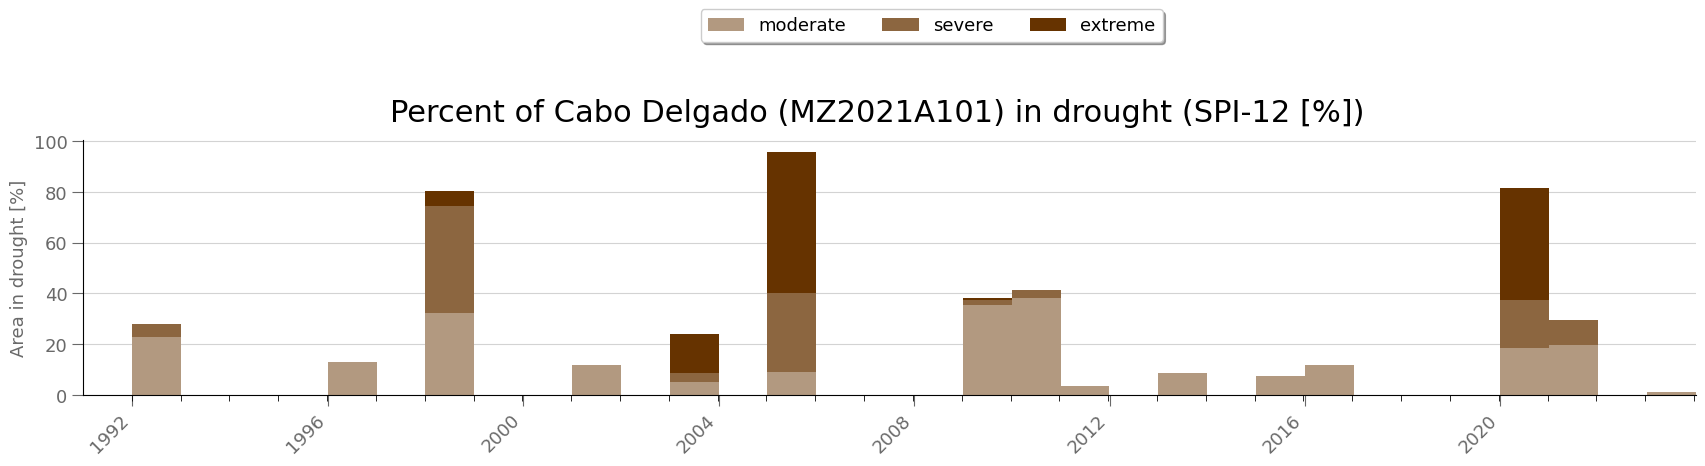

In [70]:
fig, ax1 = plt.subplots(1,1, figsize=(18,4))
fig.suptitle(f"Percent of {iadmin} ({ifnid}) in drought ({indicator}-{window} [%])", fontsize=22)
fig.tight_layout(pad=3.75)
fig.subplots_adjust(top=0.875)
font = {'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 13}

plt.rc('font', **font)

iselmon=11 # 
repeater=12

severities = ['mild','moderate','severe','extreme']
#pidata1 = pd.Series(dfdata[f'{indicator}{window}_mild'].values, index=pd.to_datetime(dfdata.index, format="%Y%m%d"))
pidata2 = pd.Series(dfdata[f'{indicator}{window}_moderate'].values, index=pd.to_datetime(dfdata.index, format="%Y%m%d"))
pidata3 = pd.Series(dfdata[f'{indicator}{window}_severe'].values, index=pd.to_datetime(dfdata.index, format="%Y%m%d"))
pidata4 = pd.Series(dfdata[f'{indicator}{window}_extreme'].values, index=pd.to_datetime(dfdata.index, format="%Y%m%d"))
#apidata = pd.concat([pidata1, pidata2, pidata3, pidata4], axis=1)
apidata = pd.concat([pidata2, pidata3, pidata4], axis=1)
print(apidata[iselmon::repeater])
#apidata.index = apidata.index.shift(-7, freq="MS") # shift datetimeindex to get ticks centered on bar
apidata.index = apidata.index.shift(-5, freq="MS") # shift datetimeindex to get ticks centered on bar
#print(apidata)
bottom = np.zeros(len(apidata.index[iselmon::repeater]))
for i in apidata.columns:
    #p = ax1.bar(pidata4.index[iselmon::repeater], apidata[i].values[iselmon::repeater], 
    #print(apidata.index[iselmon::repeater])
    p = ax1.bar(apidata.index[iselmon::repeater], apidata[i].values[iselmon::repeater], 
                width=relativedelta.relativedelta(months=window), 
                facecolor=color_list[2-i], alpha=1, label=severities[1:][i], # excluding mild
                #facecolor=color_list[3-i], alpha=1, label=severities[i], # including mild
                bottom=bottom)
    bottom += apidata[i].values[iselmon::repeater]
ax1.set_ylabel("Area in drought [%]")
ax1.legend(ncol=4, loc='upper right', bbox_to_anchor=(0.675, 1.55), fancybox=True, shadow=True)
ax1.margins(x=0)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
#ax1.spines['bottom'].set_visible(False)
#ax1.spines['left'].set_visible(False)  
ax1.tick_params(axis='both', colors='dimgrey')
ax1.xaxis.label.set_color('dimgrey')
ax1.yaxis.label.set_color('dimgrey')
ax1.xaxis.set_minor_locator(MultipleLocator(365)) # does not account for leap years
#ax1.xaxis.set_minor_locator(apidata.index.YearLocator())
#ax1.xaxis.set_major_locator(apidata.index.YearLocator(10))
date_form = DateFormatter("%Y")
ax1.xaxis.set_major_formatter(date_form)
ax1.tick_params(which='minor', length=4)
ax1.tick_params(which='major', length=8)
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=30, ha='right')
#ax1.grid(True)
ax1.set_axisbelow(True)
ax1.yaxis.grid(color='lightgray', linestyle='solid') #dashed
for tick in ax1.get_xticklabels():
    tick.set_rotation(45)
    
figname=f"MOZ_WFS_0001_{indicator}{window}_19910101_20231201_AID_{ifnid}.png"
print(figname)
plt.savefig(figname, dpi='figure', format=None, metadata=None,
    bbox_inches=None, pad_inches=0.1,
    facecolor='auto', edgecolor='auto',
    backend=None)

### ADMIN2 - DATA

#### Read ADMIN shp and get all ADMIN IDs

In [23]:
shppath="/ec/vol/centaur/wfs_data/0_FEWSNET_ADMIN/ColdCases"
adminshp=f"{shppath}/MZ_Admin2_2021.shp"

# Open the shapefile with gpd
shapefile=gpd.read_file(adminshp)
#print(shapefile)
print(shapefile['ADMIN1'])
print(shapefile['FNID'])
fnids = shapefile['FNID']

0          Zambezia
1           Nampula
2      Cabo Delgado
3           Nampula
4              Tete
           ...     
155       Inhambane
156            Tete
157          Niassa
158          Niassa
159          Niassa
Name: ADMIN1, Length: 160, dtype: object
0      MZ2021A21101
1      MZ2021A20724
2      MZ2021A20101
3      MZ2021A20701
4      MZ2021A21001
           ...     
155    MZ2021A20314
156    MZ2021A21015
157    MZ2021A20807
158    MZ2021A20805
159    MZ2021A20804
Name: FNID, Length: 160, dtype: object


#### Test masking for each ADMIN

MZ2021A21101
Processing SPI-1


/etc/ecmwf/ssd/ssd1/tmpdirs/nejk.16028810/ipykernel_3159471/1254368403.py:79: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  aid_spi_ecm[ivar] = pd.concat([aid_spi_ecm[ivar], pd.Series({'aid': tmp.values[0]})], ignore_index=True)
/etc/ecmwf/ssd/ssd1/tmpdirs/nejk.16028810/ipykernel_3159471/1254368403.py:79: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  aid_spi_ecm[ivar] = pd.concat([aid_spi_ecm[ivar], pd.Series({'aid': tmp.values[0]})], ignore_index=True)
/etc/ecmwf/ssd/ssd1/tmpdirs/nejk.16028810/ipykernel_3159471/1254368403.py:79: FutureWarning: The behav

-0.6129686590243928
-0.4734691444441662
-0.07259296499452433
-0.6129686590243928
-0.4734691444441662
-0.07259296499452433
-0.6129686590243928
-0.4734691444441662
-0.07259296499452433
1.0399117390059074
1.1662750197007485
8.209536151601387
1.0399117390059074
1.1662750197007485
8.209536151601387
1.0399117390059074
1.1662750197007485
8.209536151601387
0.7352655317111828
0.8550823802935832
0.9802281649238263
0.7352655317111828
0.8550823802935832
0.9802281649238263
0.7352655317111828
0.8550823802935832
0.9802281649238263
-0.49298854386748436
-0.20005315934801354
0.08522762726439793
-0.49298854386748436
-0.20005315934801354
0.08522762726439793
-0.49298854386748436
-0.20005315934801354
0.08522762726439793
-1.033513131030802
-0.6396543026921686
-0.4380117160653755
-1.033513131030802
-0.6396543026921686
-0.4380117160653755
-1.033513131030802
-0.6396543026921686
-0.4380117160653755
0.1327906913109427
0.2850440244104643
0.6368985298147674
0.1327906913109427
0.2850440244104643
0.6368985298147674
0

/etc/ecmwf/ssd/ssd1/tmpdirs/nejk.16028810/ipykernel_3159471/1254368403.py:79: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  aid_spi_ecm[ivar] = pd.concat([aid_spi_ecm[ivar], pd.Series({'aid': tmp.values[0]})], ignore_index=True)
/etc/ecmwf/ssd/ssd1/tmpdirs/nejk.16028810/ipykernel_3159471/1254368403.py:79: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  aid_spi_ecm[ivar] = pd.concat([aid_spi_ecm[ivar], pd.Series({'aid': tmp.values[0]})], ignore_index=True)
/etc/ecmwf/ssd/ssd1/tmpdirs/nejk.16028810/ipykernel_3159471/1254368403.py:79: FutureWarning: The behav

-0.764064603537173
-0.764064603537173
-0.764064603537173
-0.764064603537173
-0.764064603537173
-0.764064603537173
-0.764064603537173
-0.764064603537173
-0.764064603537173
1.0324095607090127
1.0324095607090127
1.0324095607090127
1.0324095607090127
1.0324095607090127
1.0324095607090127
1.0324095607090127
1.0324095607090127
1.0324095607090127
1.6773744552470369
1.6773744552470369
1.6773744552470369
1.6773744552470369
1.6773744552470369
1.6773744552470369
1.6773744552470369
1.6773744552470369
1.6773744552470369
0.9576260495916442
0.9576260495916442
0.9576260495916442
0.9576260495916442
0.9576260495916442
0.9576260495916442
0.9576260495916442
0.9576260495916442
0.9576260495916442
-0.079467791701262
-0.079467791701262
-0.079467791701262
-0.079467791701262
-0.079467791701262
-0.079467791701262
-0.079467791701262
-0.079467791701262
-0.079467791701262
0.07084206065439574
0.07084206065439574
0.07084206065439574
0.07084206065439574
0.07084206065439574
0.07084206065439574
0.07084206065439574
0.070

/etc/ecmwf/ssd/ssd1/tmpdirs/nejk.16028810/ipykernel_3159471/1254368403.py:79: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  aid_spi_ecm[ivar] = pd.concat([aid_spi_ecm[ivar], pd.Series({'aid': tmp.values[0]})], ignore_index=True)
/etc/ecmwf/ssd/ssd1/tmpdirs/nejk.16028810/ipykernel_3159471/1254368403.py:79: FutureWarning: The behavior of array concatenation with empty entries is deprecated. In a future version, this will no longer exclude empty items when determining the result dtype. To retain the old behavior, exclude the empty entries before the concat operation.
  aid_spi_ecm[ivar] = pd.concat([aid_spi_ecm[ivar], pd.Series({'aid': tmp.values[0]})], ignore_index=True)
/etc/ecmwf/ssd/ssd1/tmpdirs/nejk.16028810/ipykernel_3159471/1254368403.py:79: FutureWarning: The behav

... (307 outputs left out)

/usr/local/apps/python3/3.11.8-01/lib/python3.11/site-packages/regionmask/core/_deprecate.py:108: UserWarning: No gridpoint belongs to any region. Returning an all-NaN mask.
  return func(*args, **kwargs)


0
MZ2021A20804


/usr/local/apps/python3/3.11.8-01/lib/python3.11/site-packages/regionmask/core/_deprecate.py:108: UserWarning: No gridpoint belongs to any region. Returning an all-NaN mask.
  return func(*args, **kwargs)


0


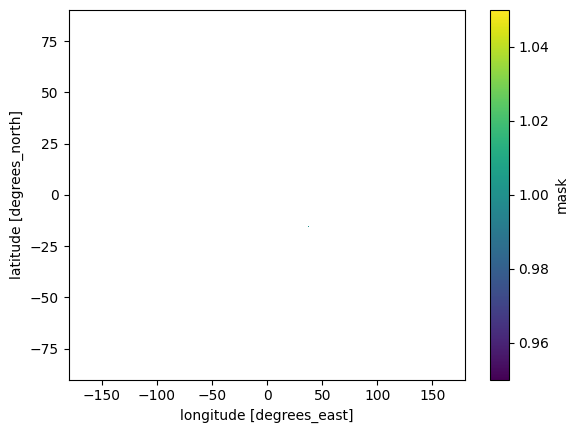

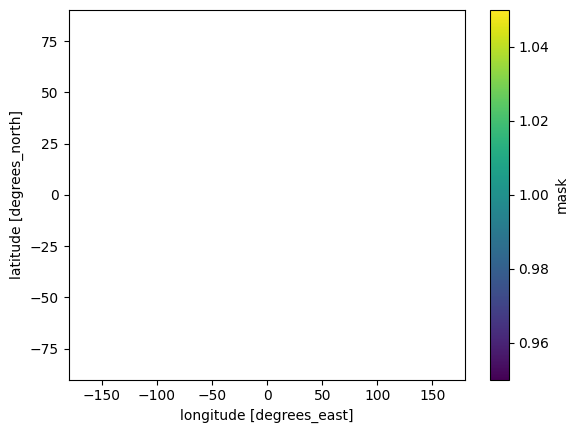

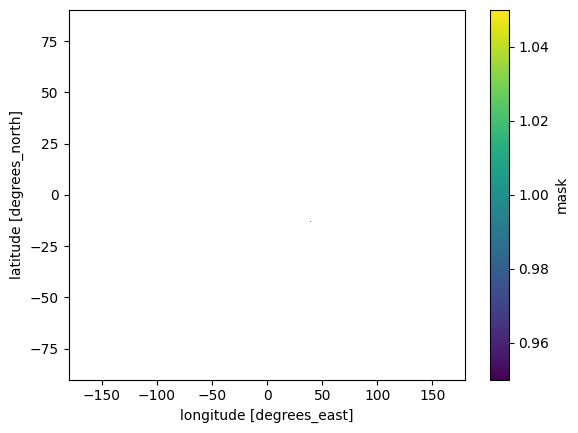

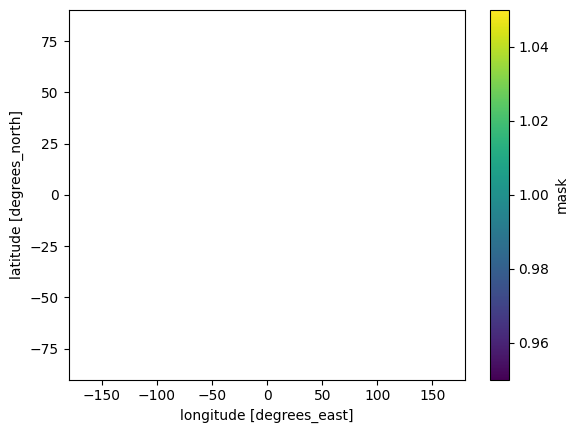

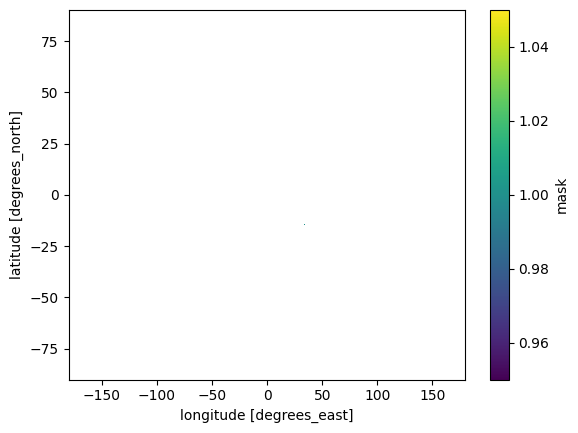

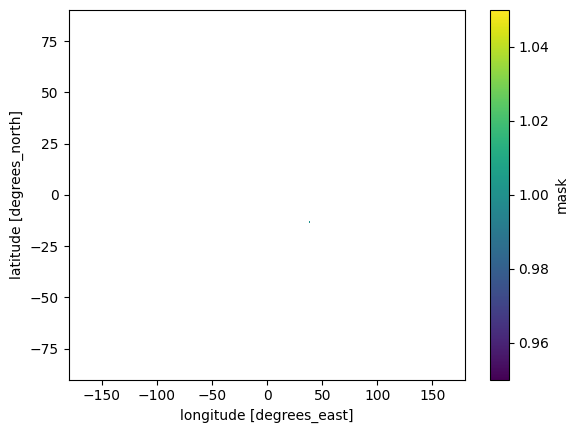

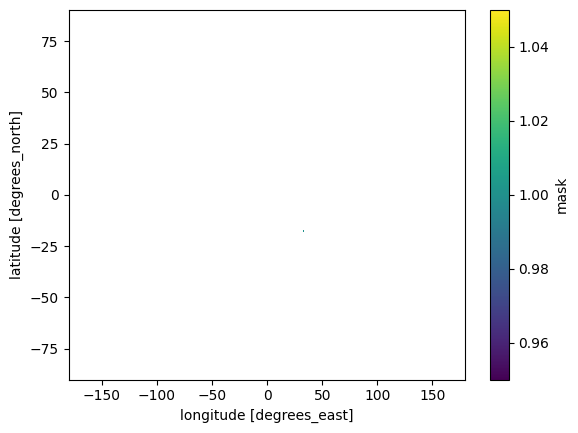

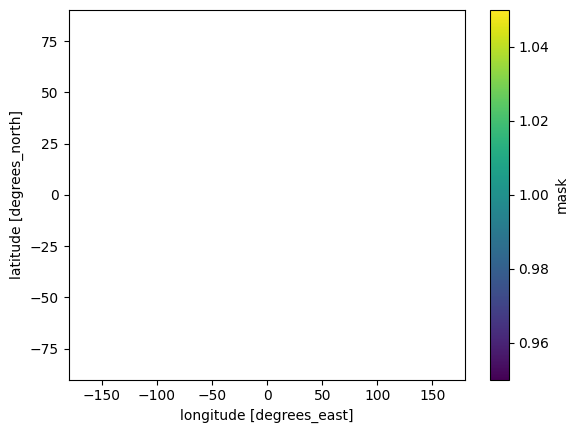

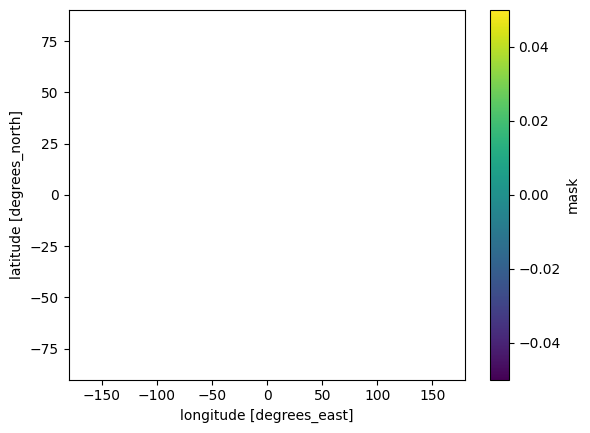

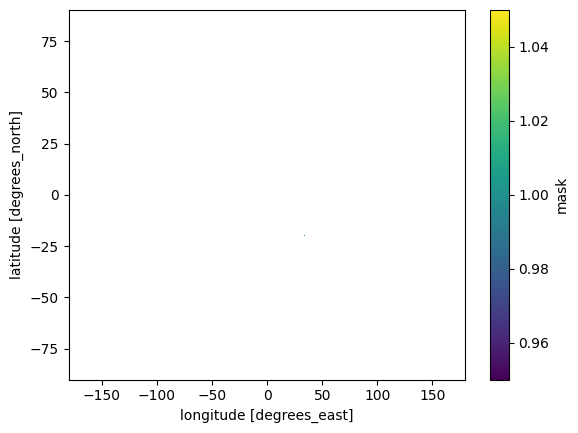

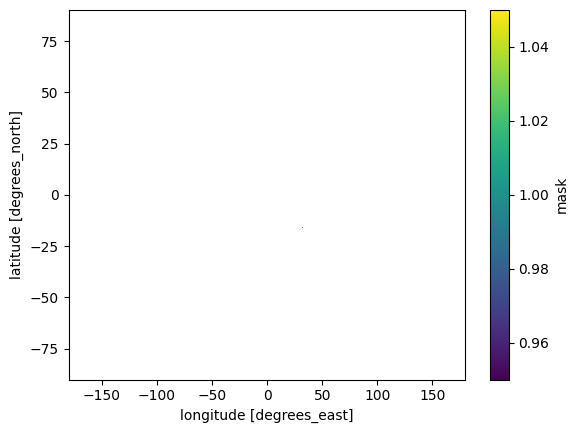

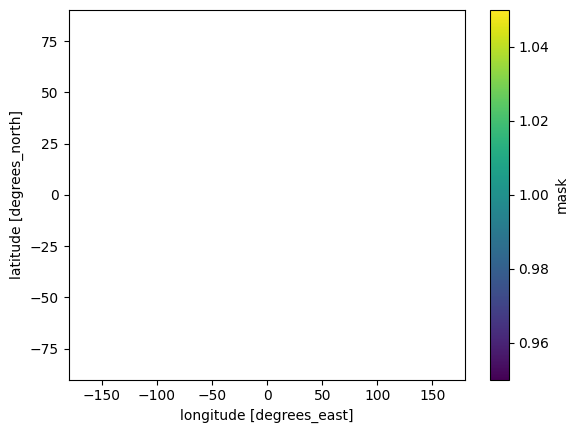

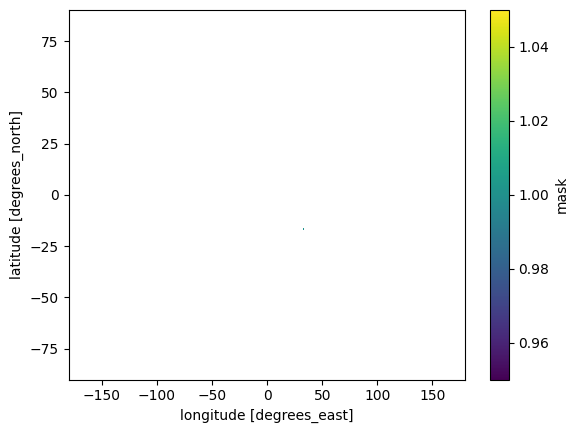

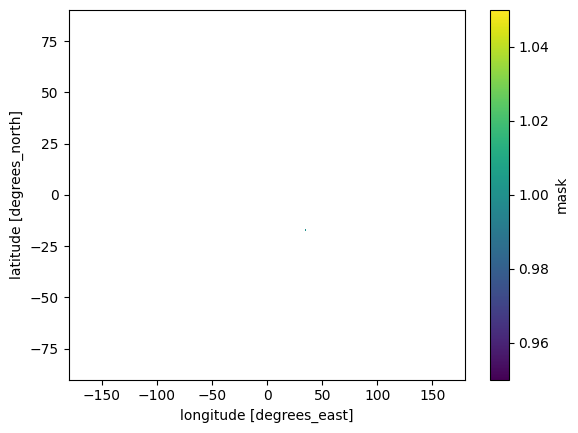

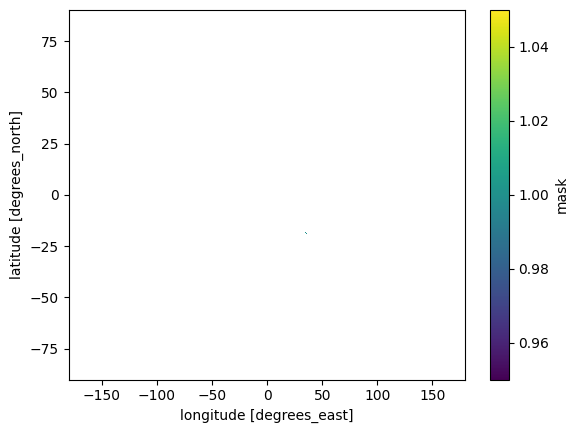

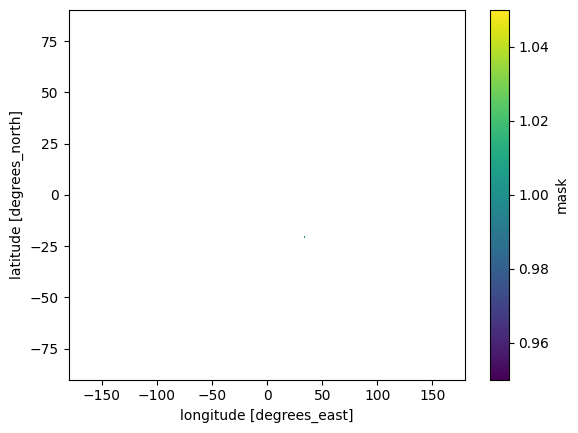

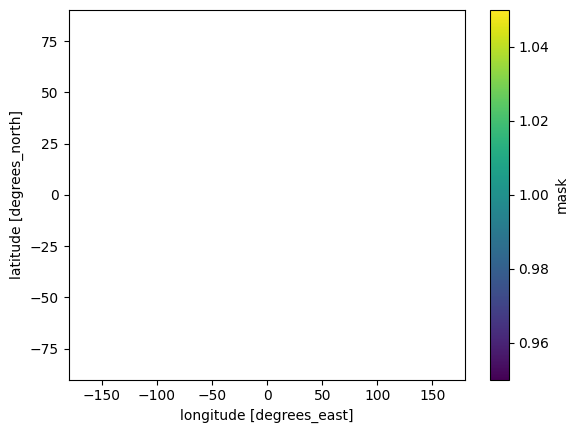

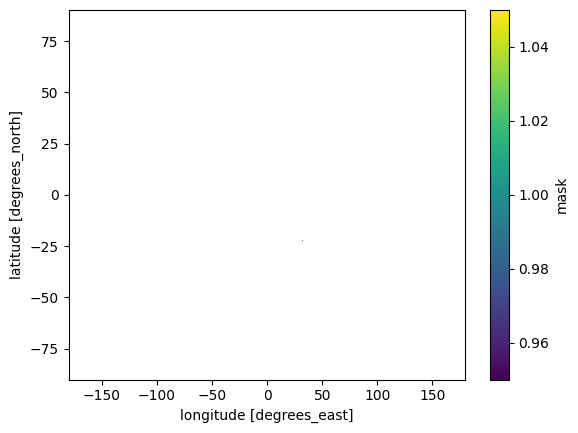

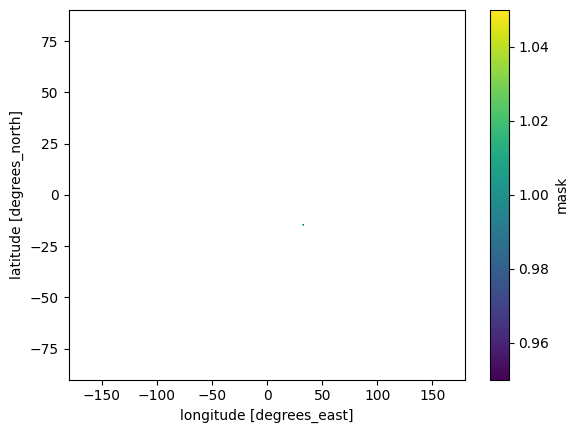

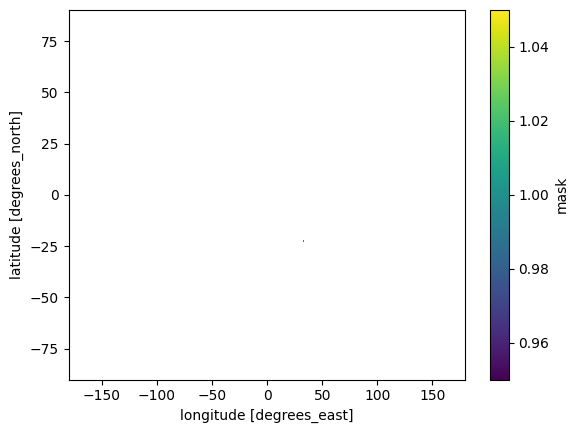

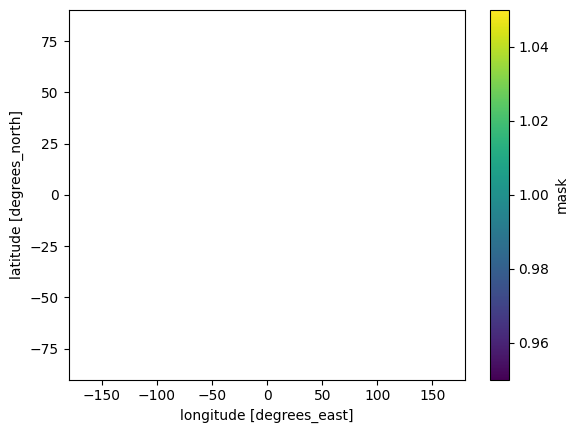

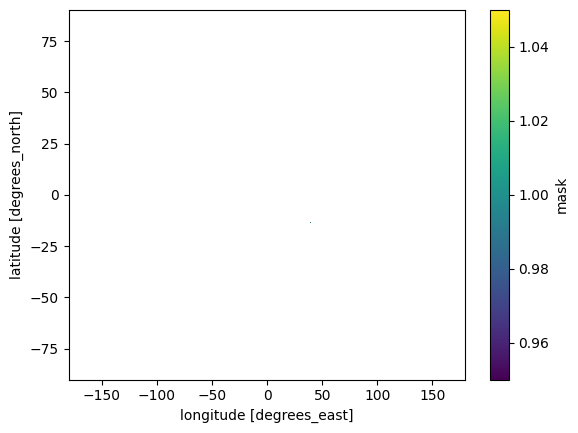

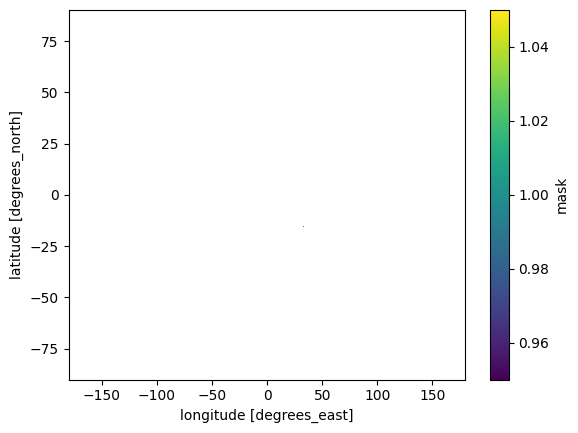

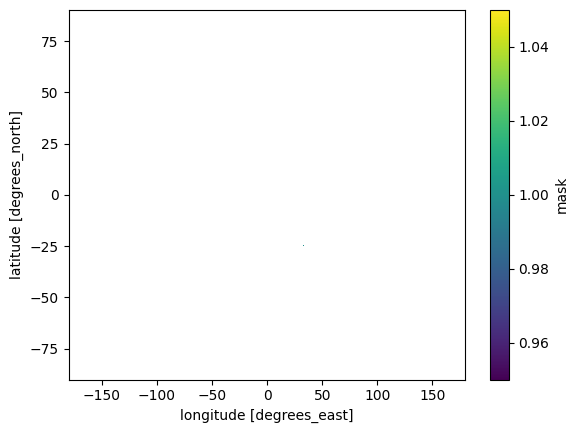

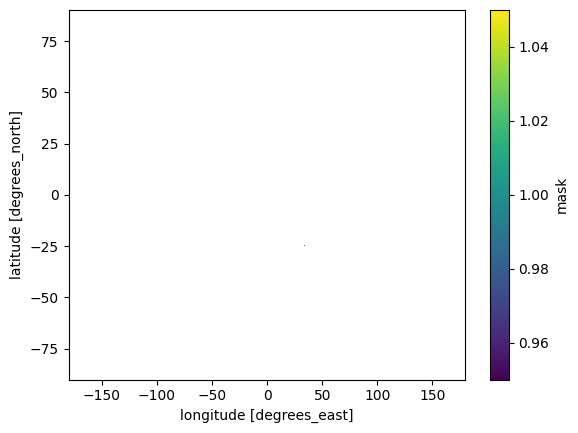

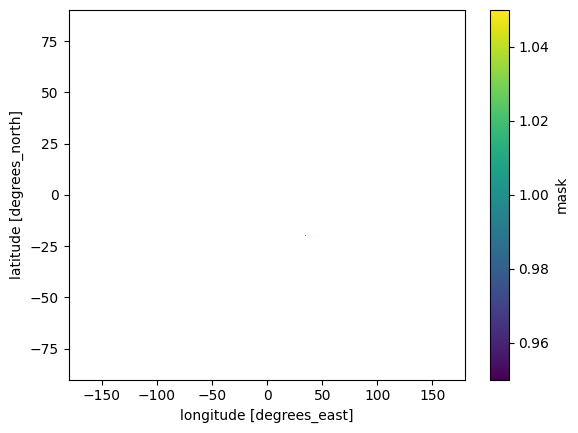

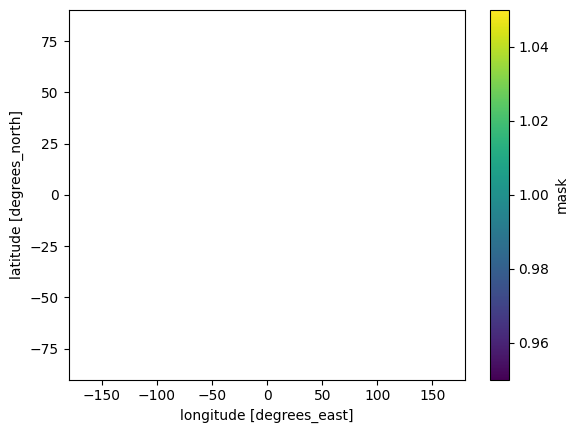

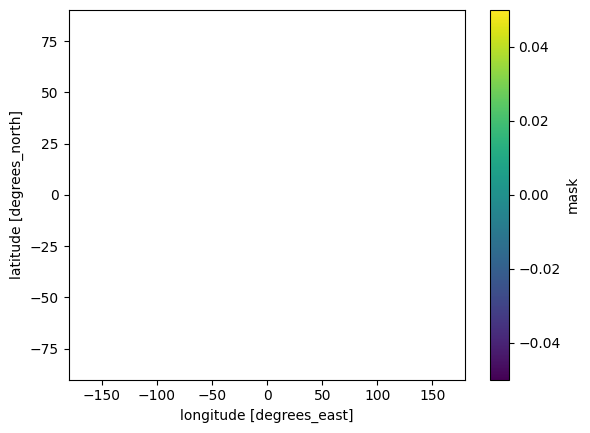

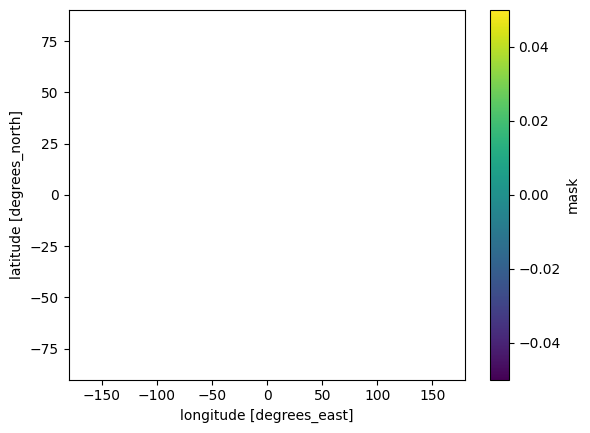

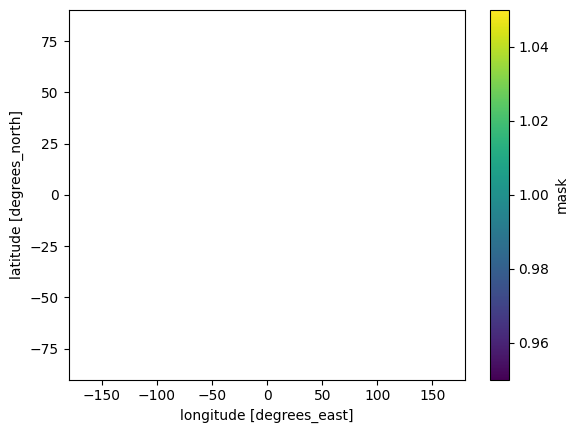

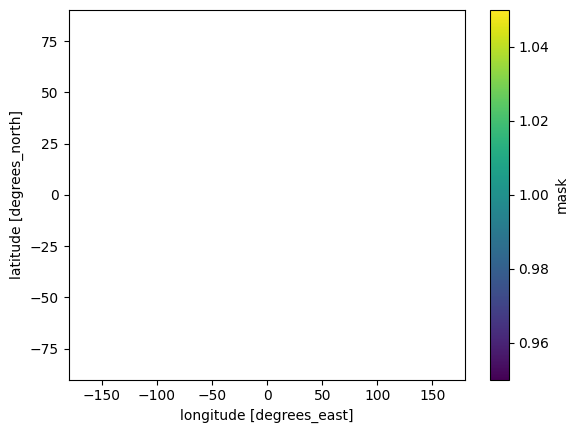

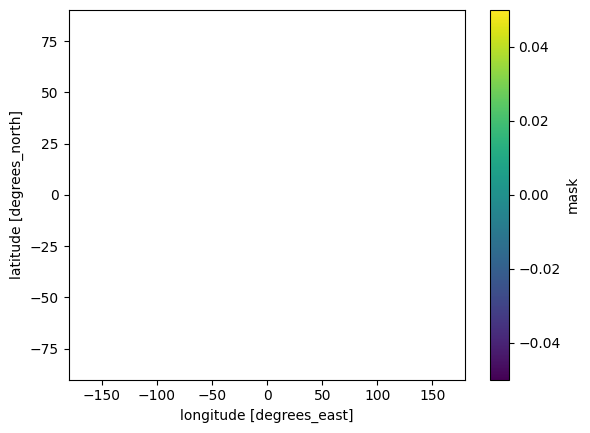

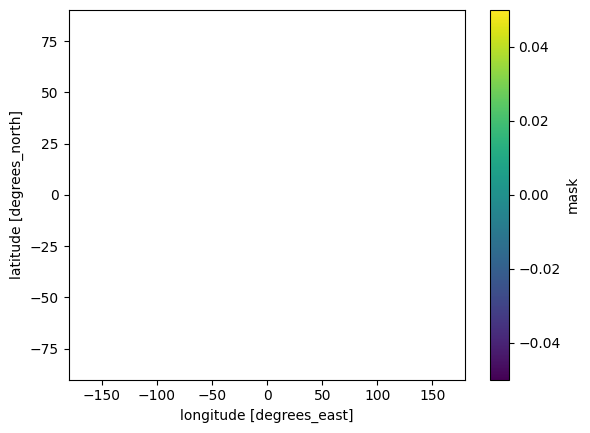

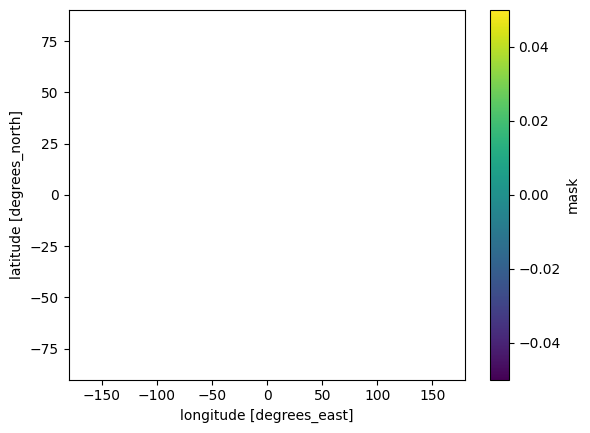

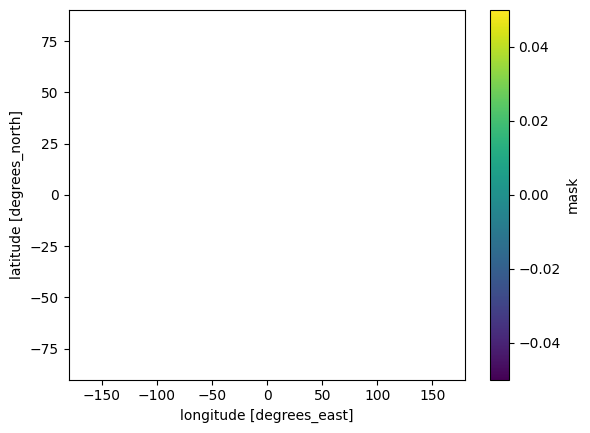

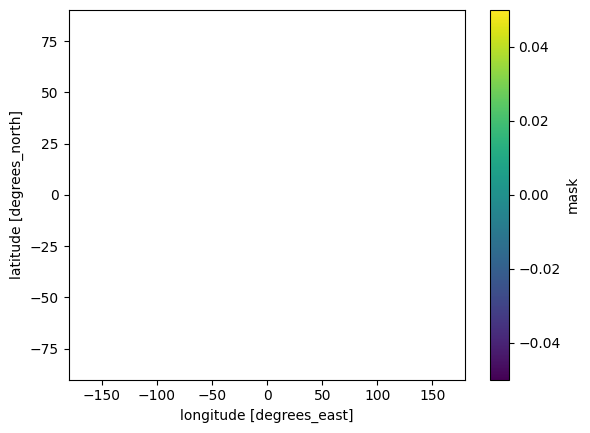

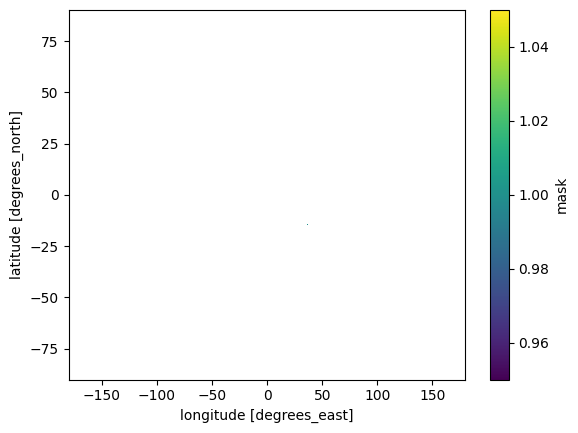

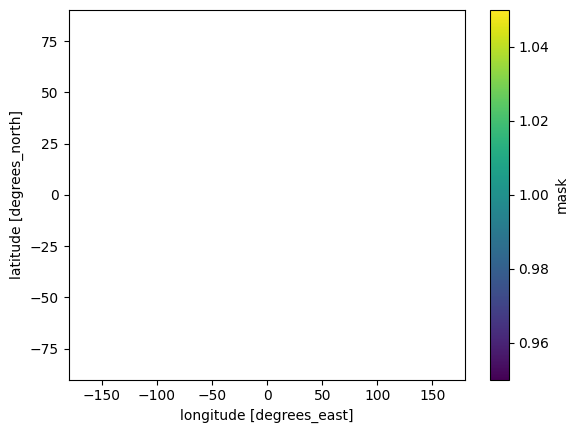

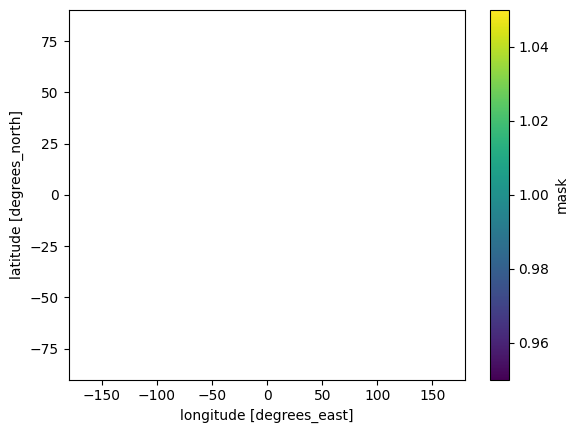

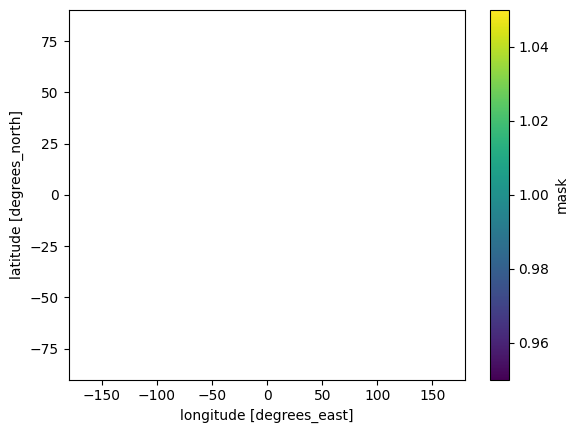

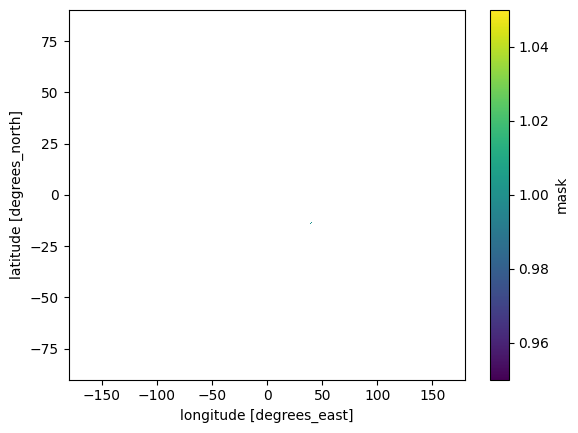

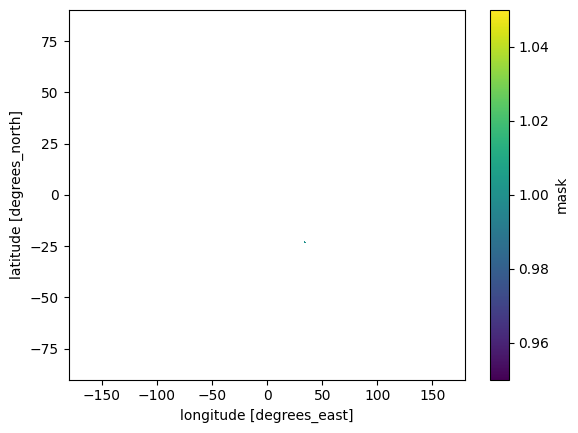

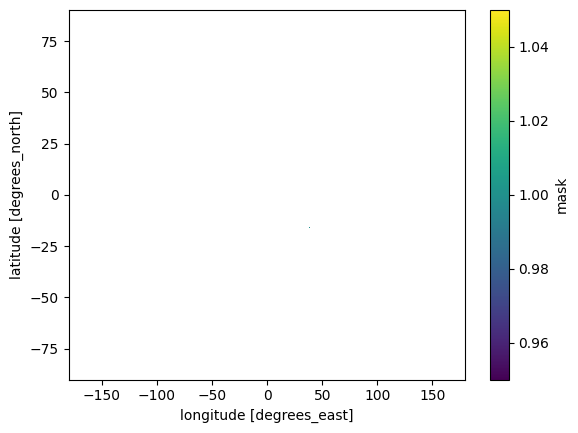

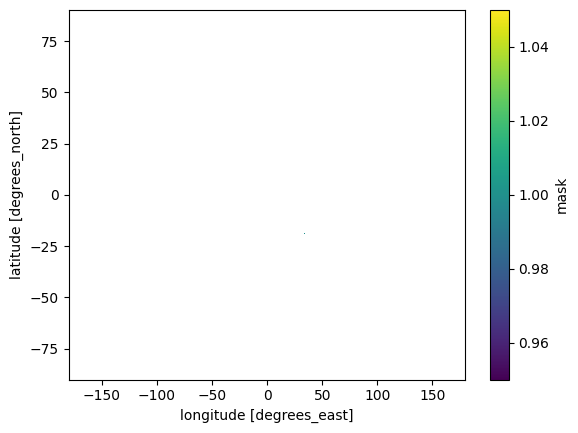

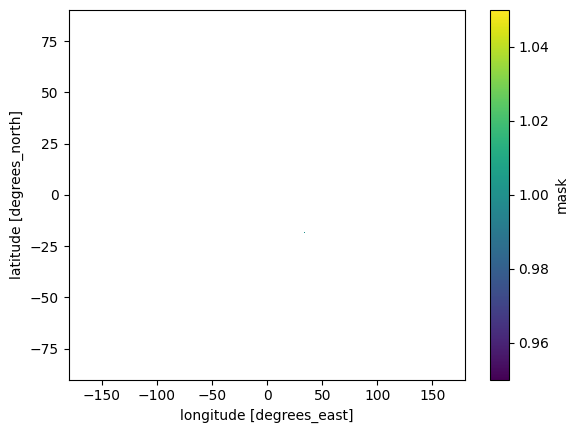

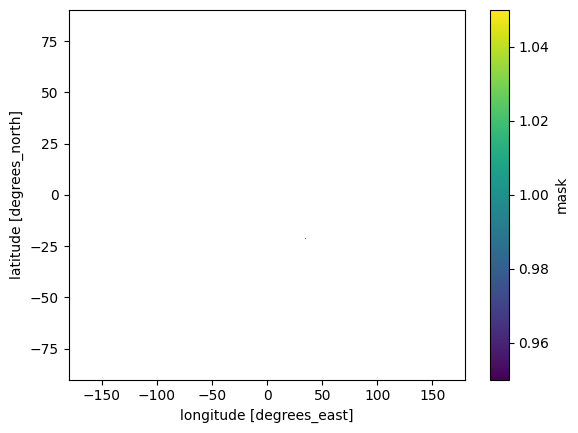

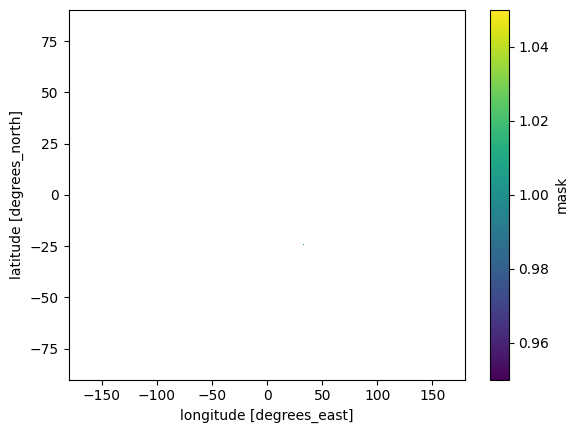

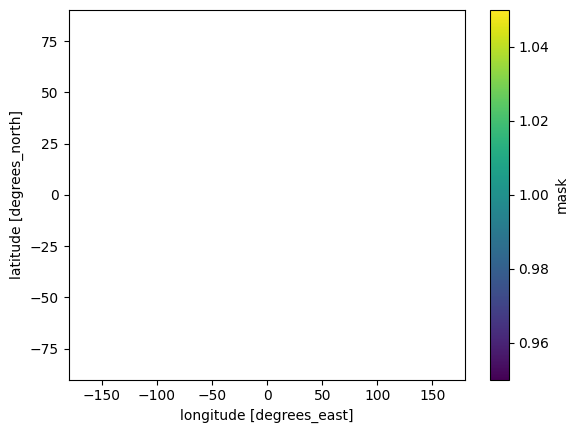

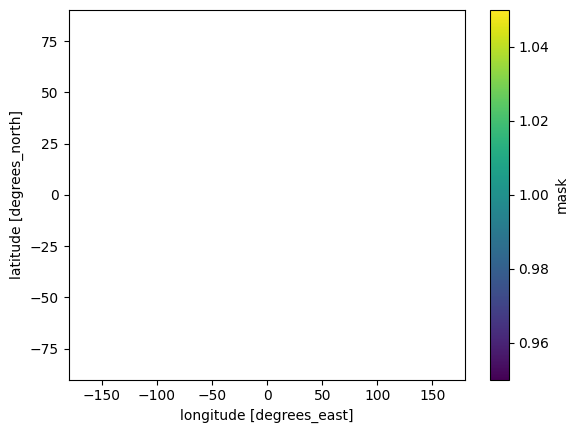

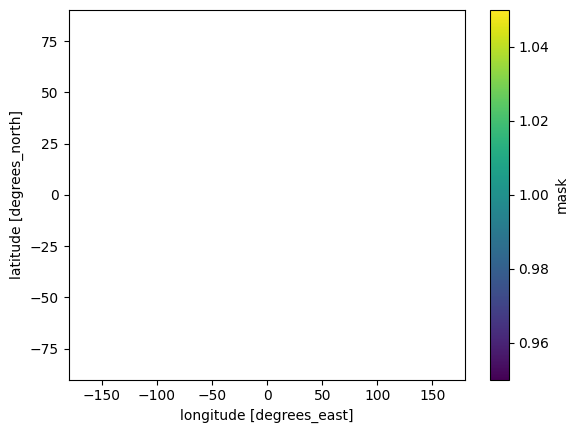

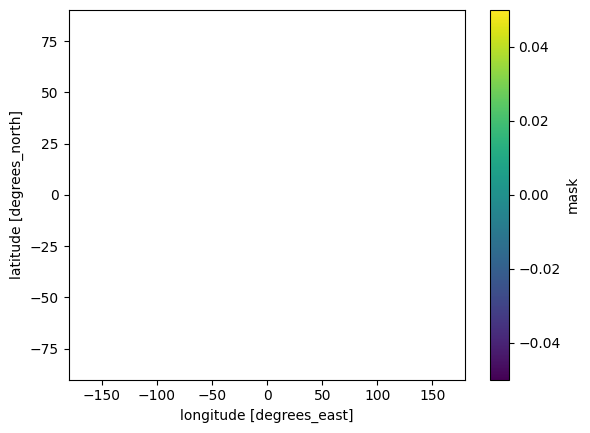

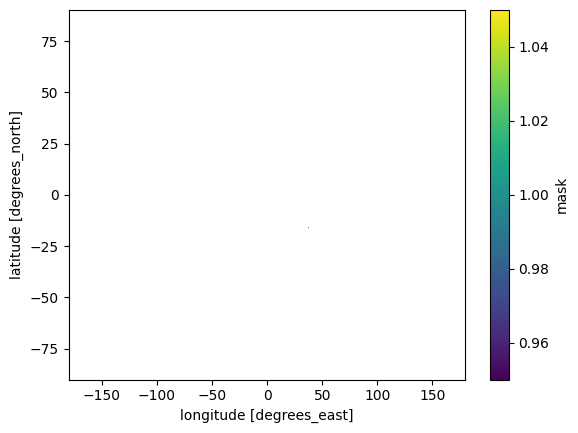

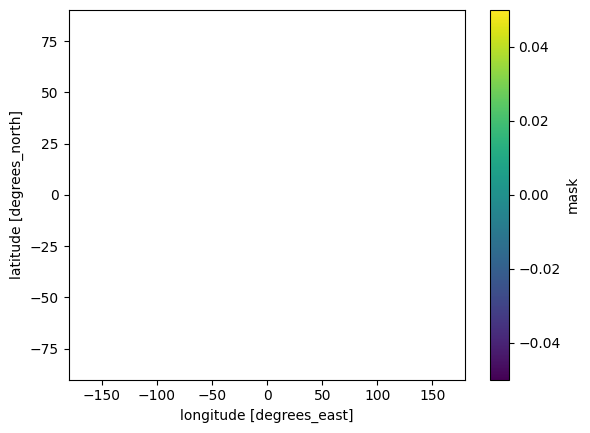

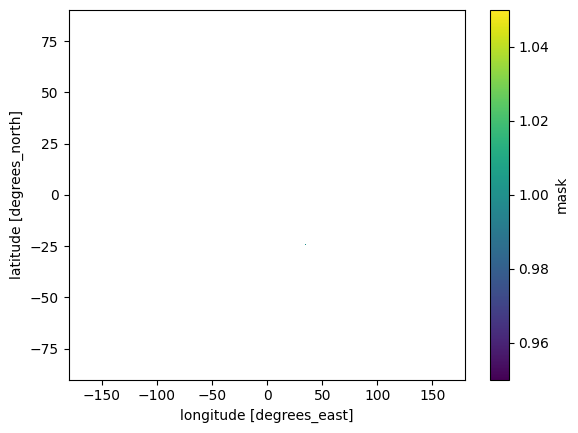

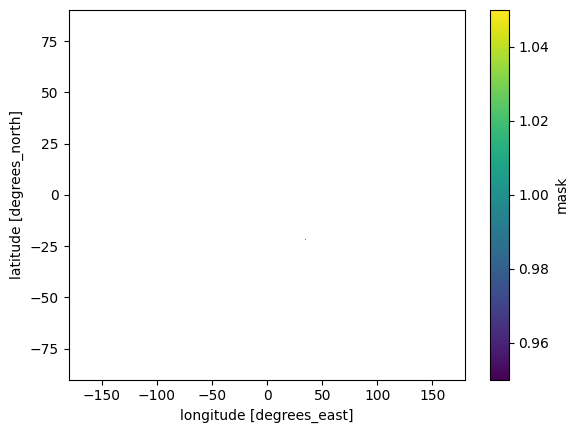

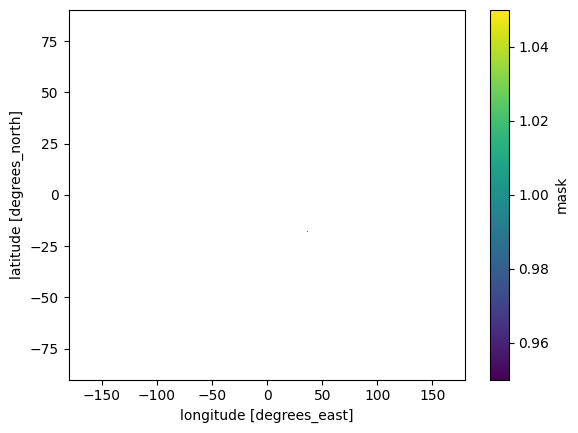

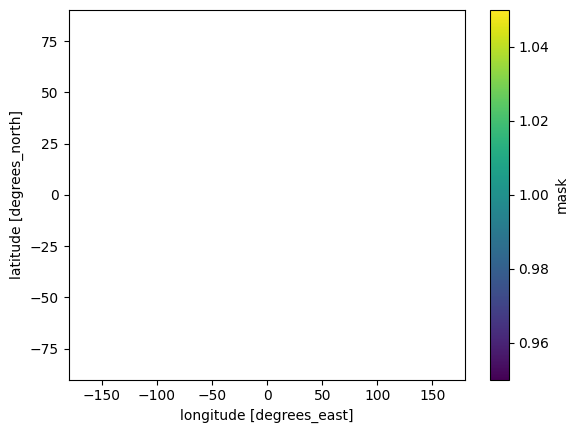

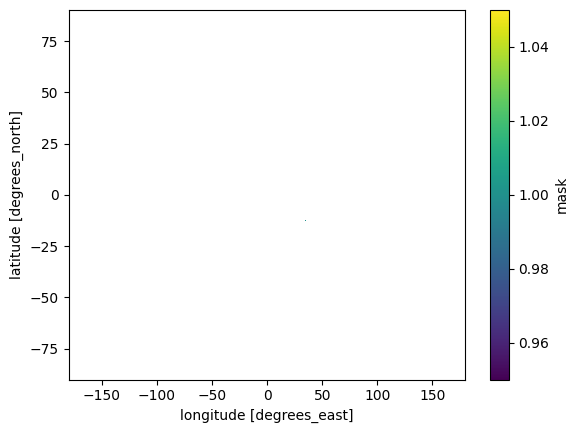

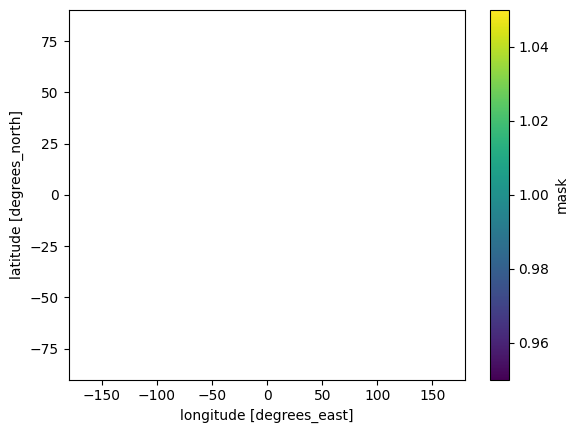

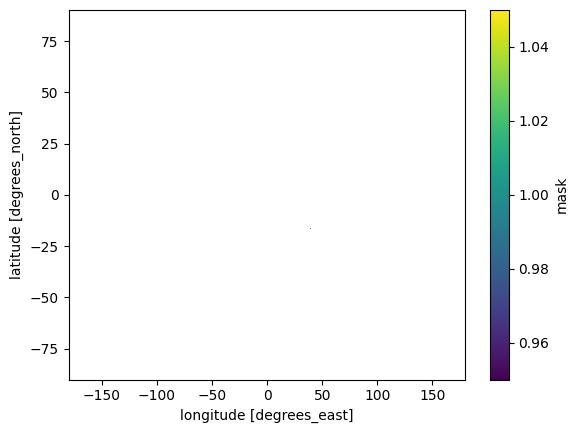

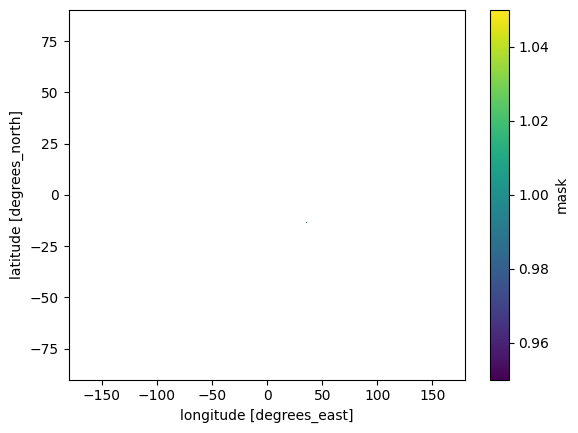

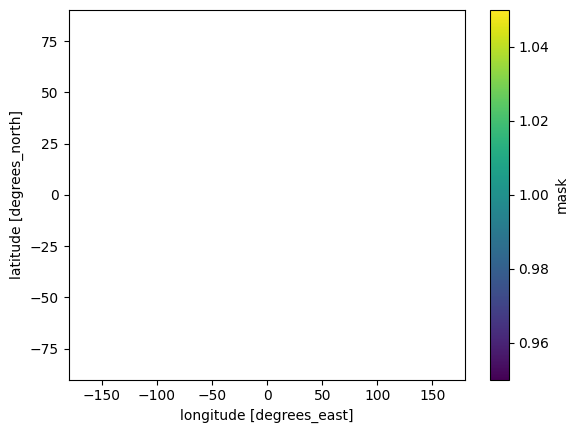

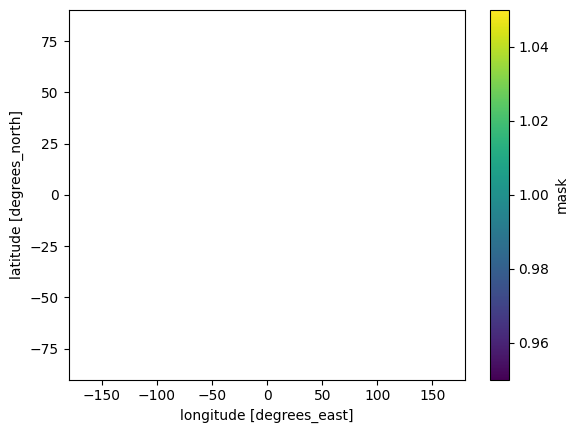

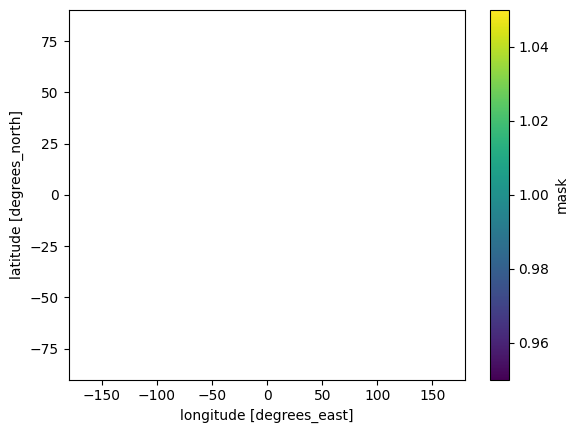

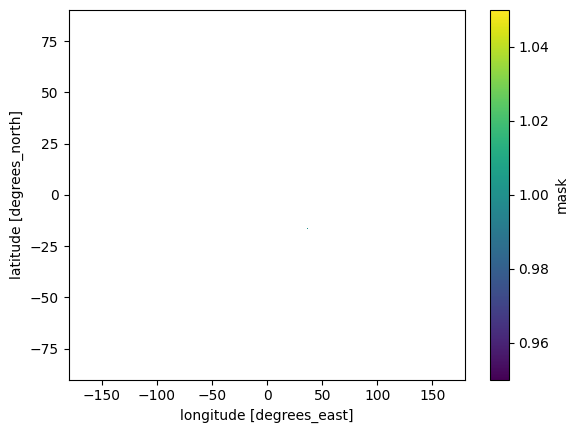

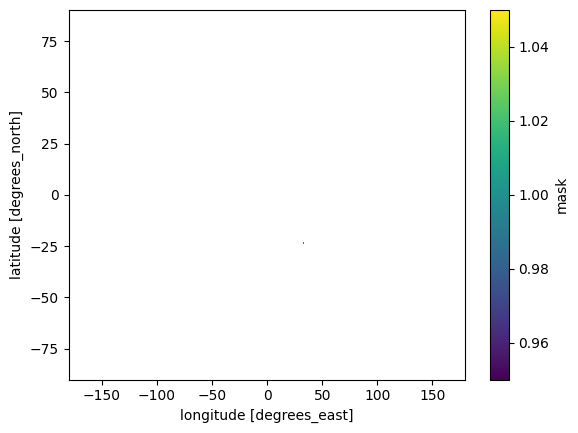

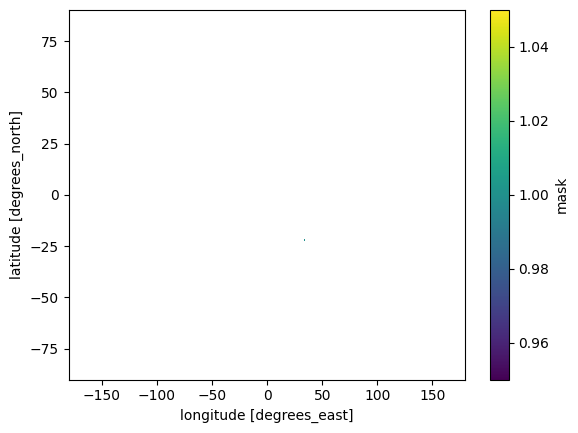

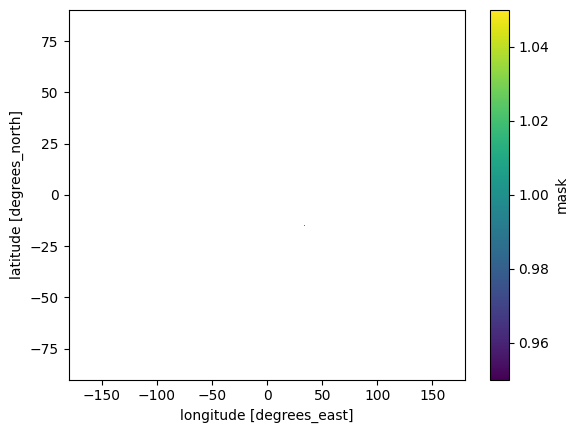

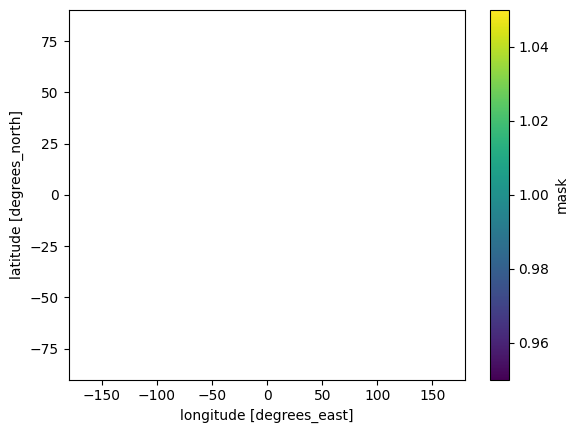

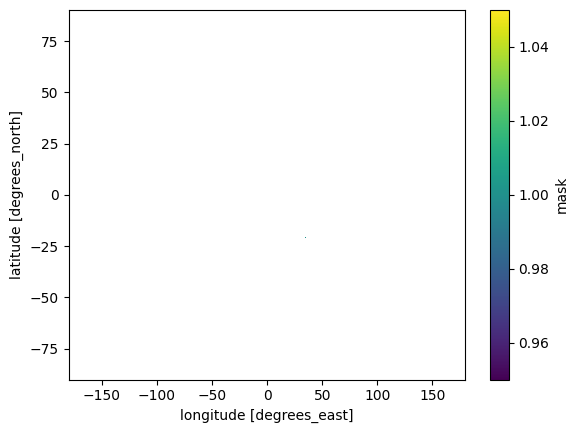

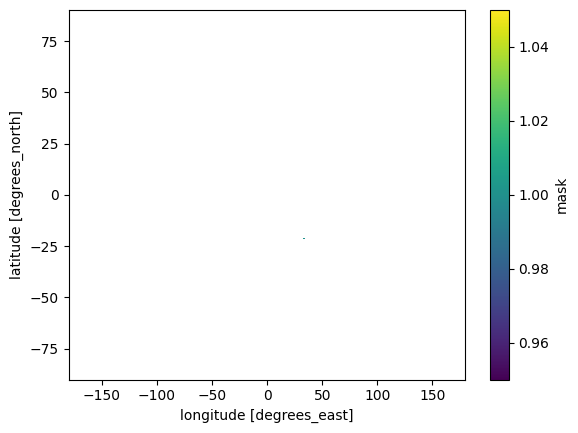

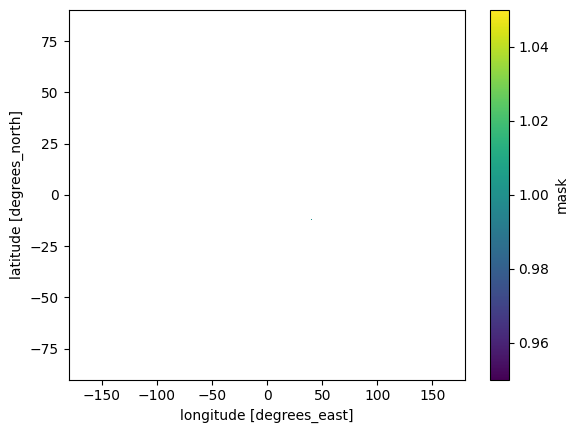

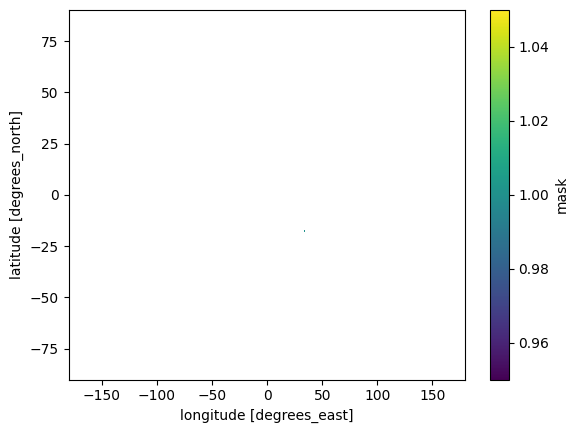

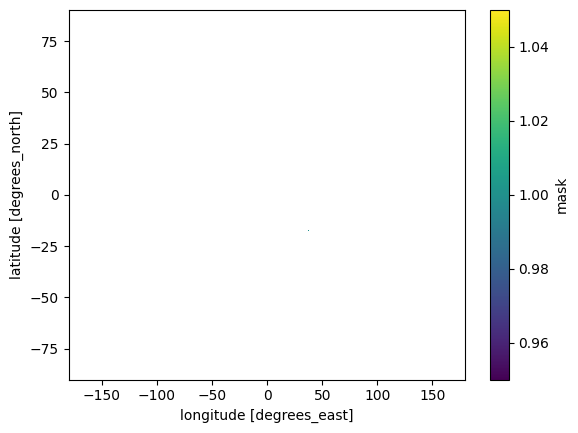

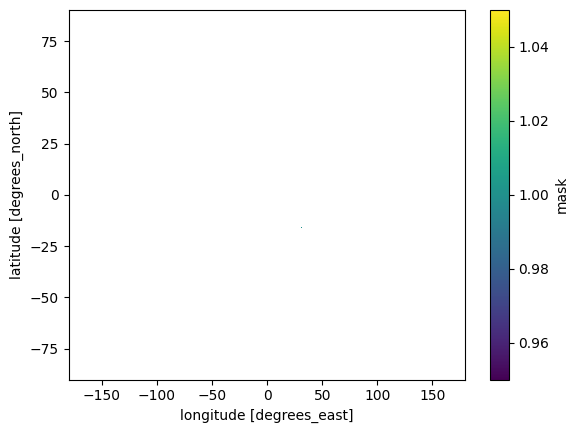

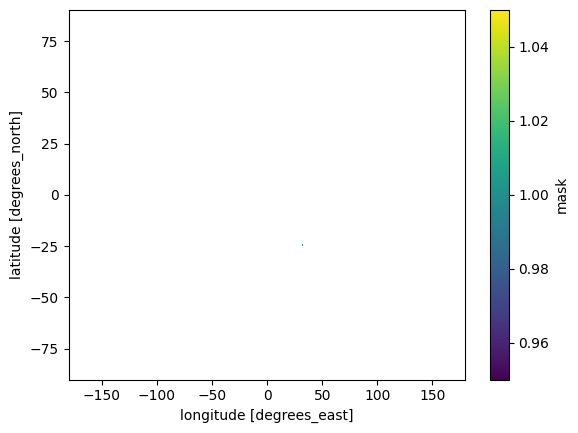

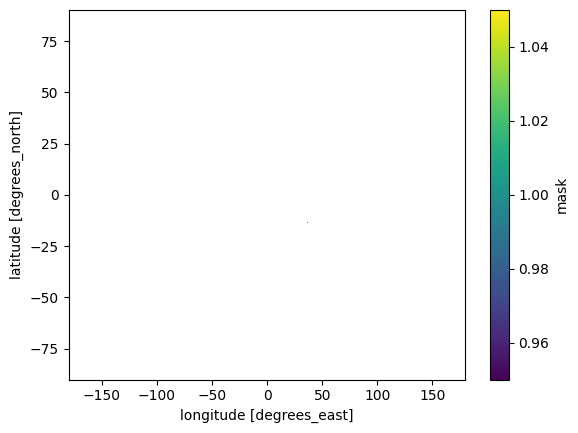

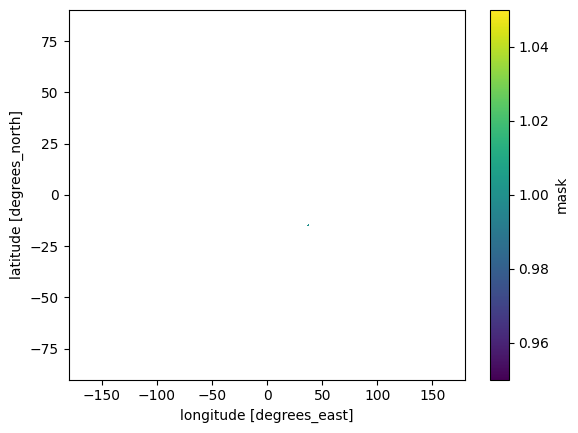

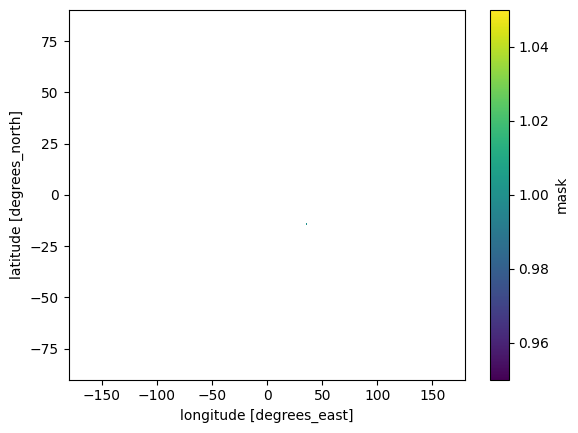

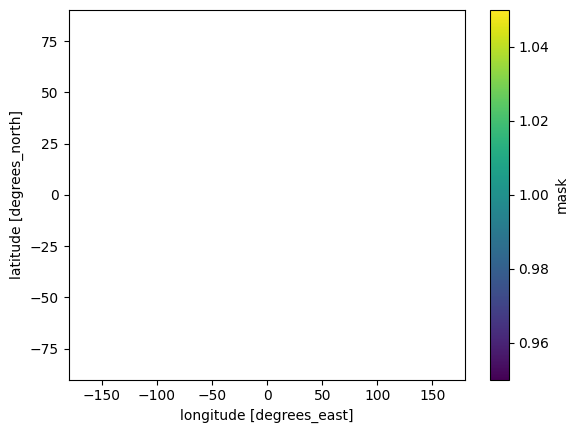

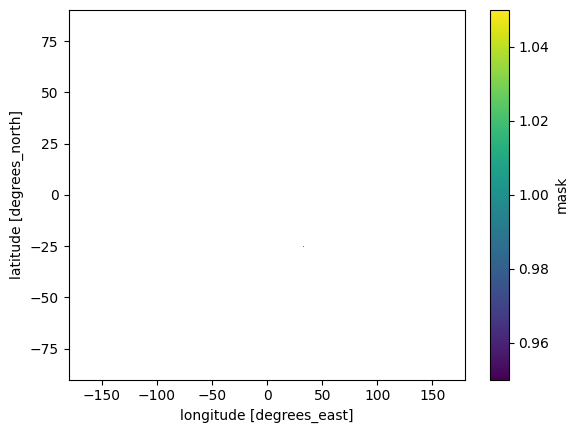

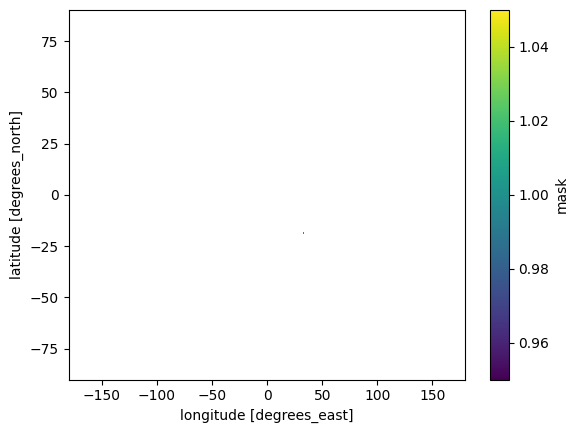

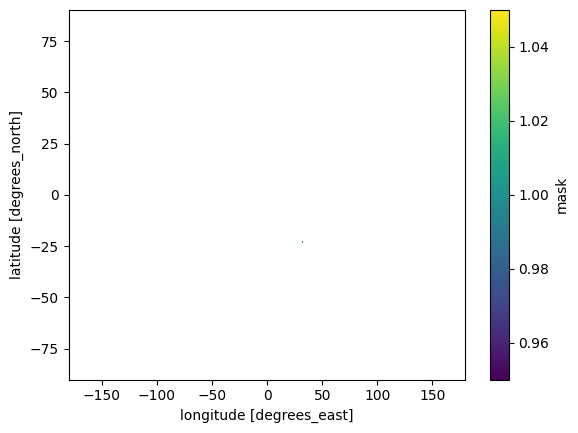

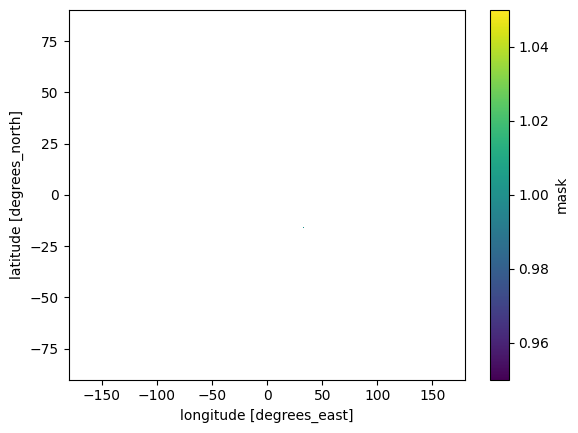

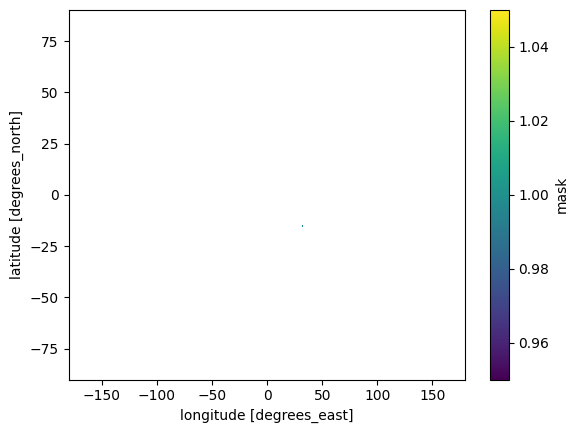

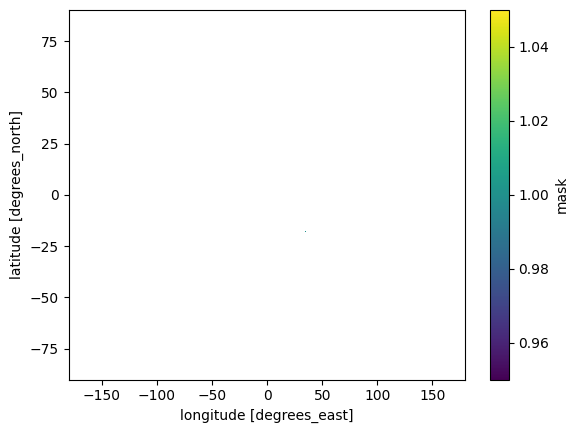

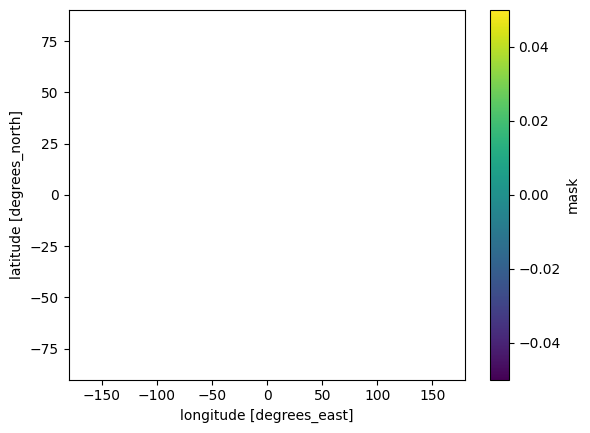

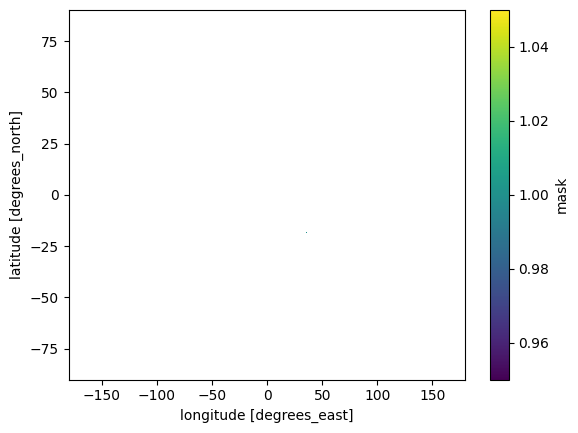

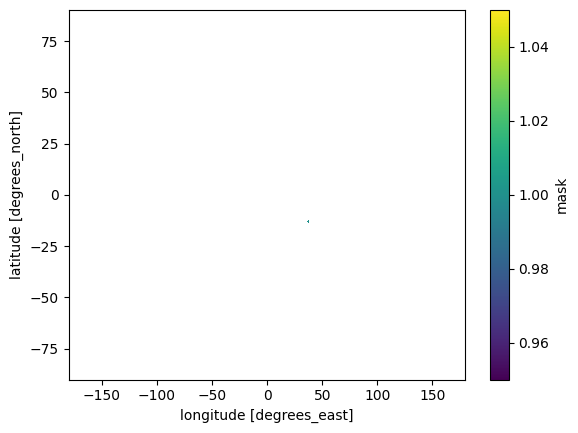

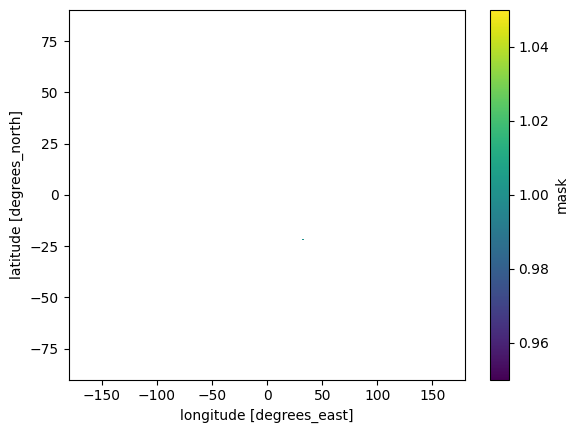

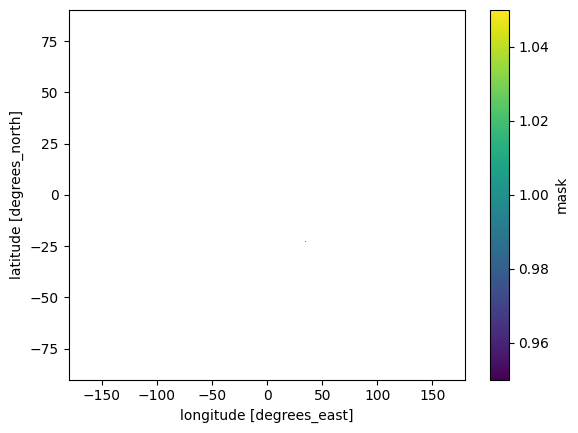

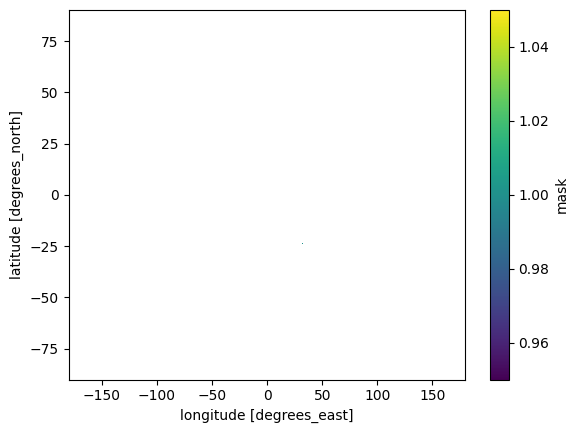

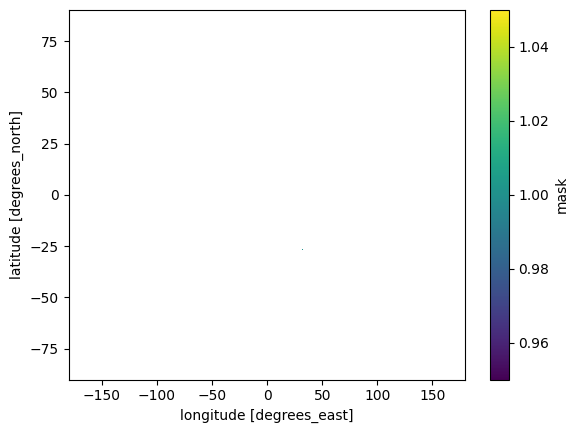

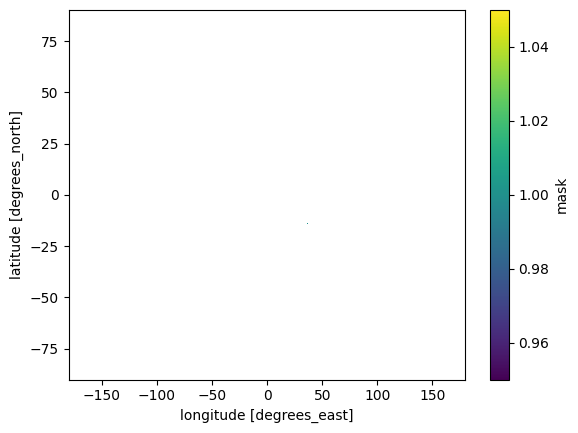

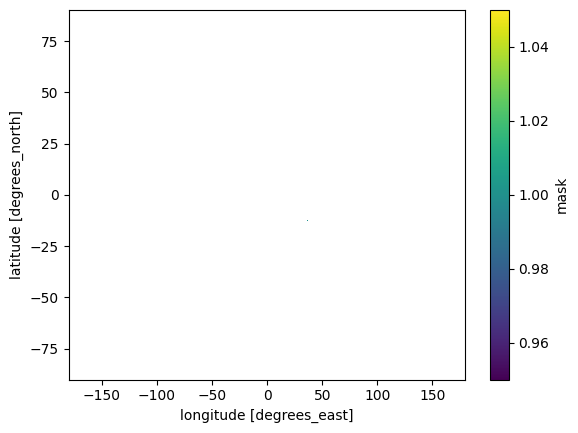

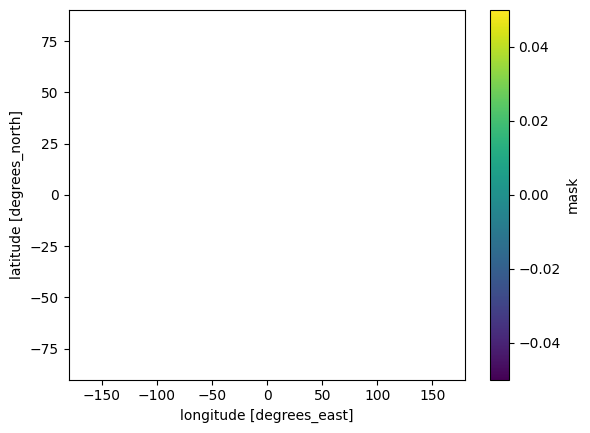

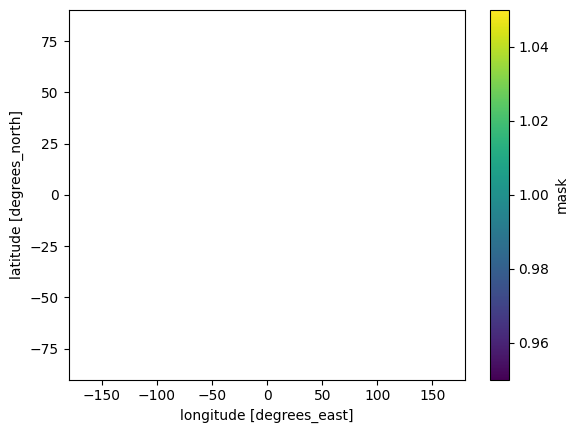

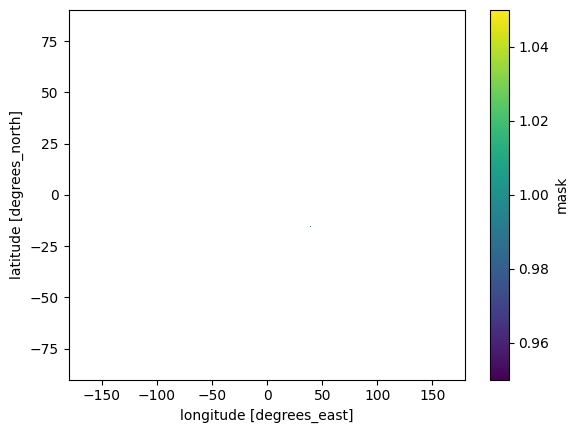

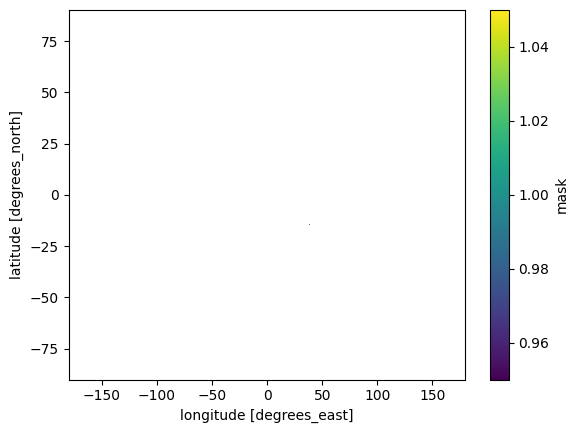

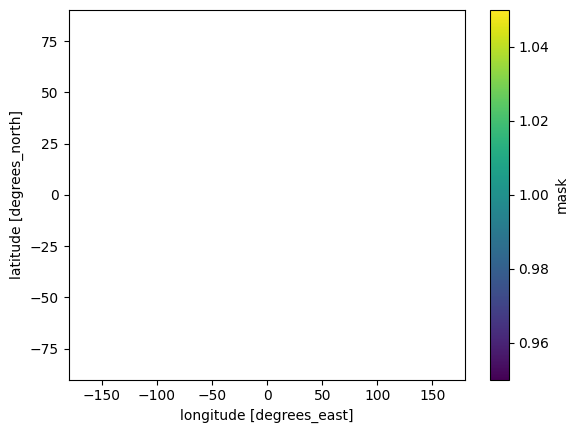

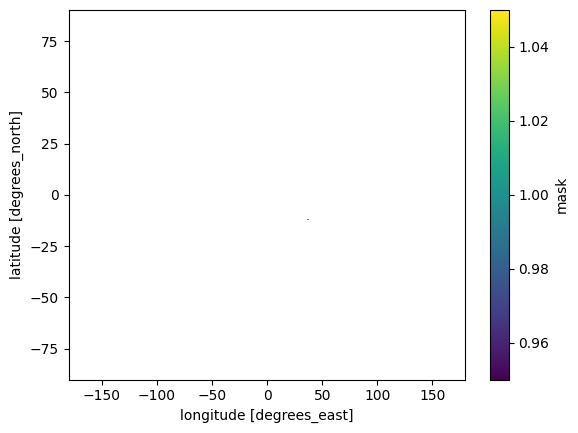

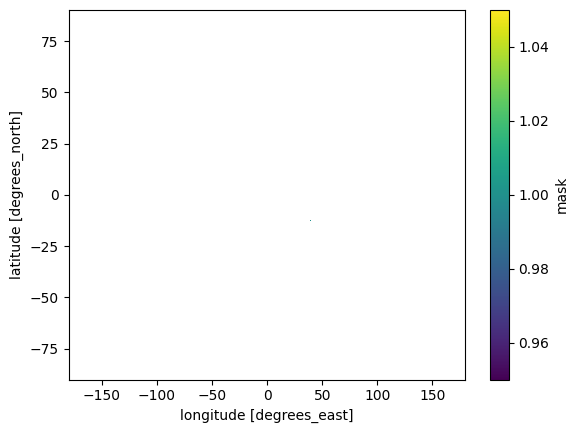

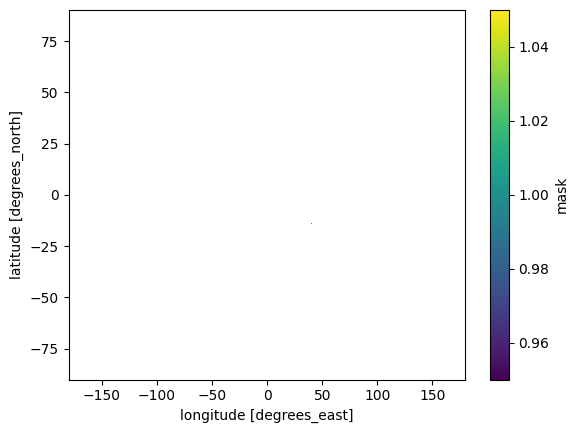

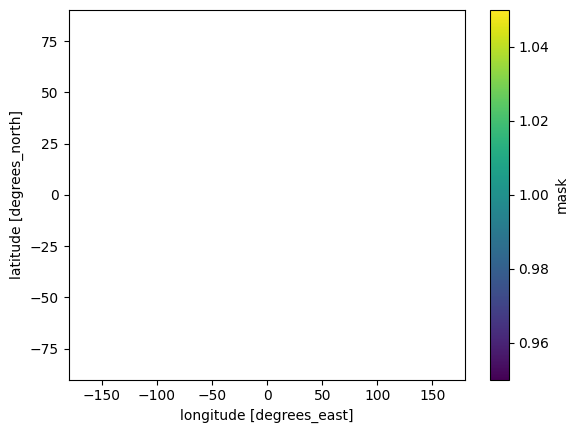

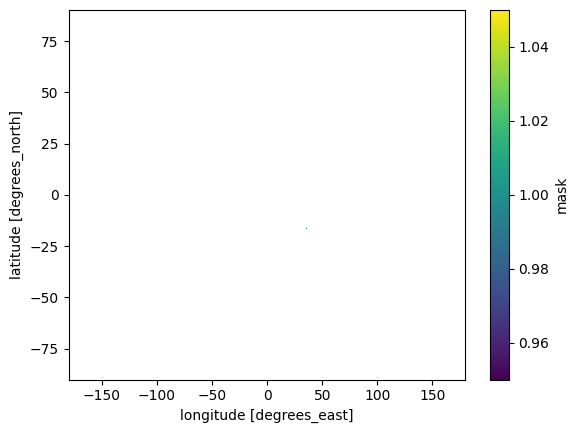

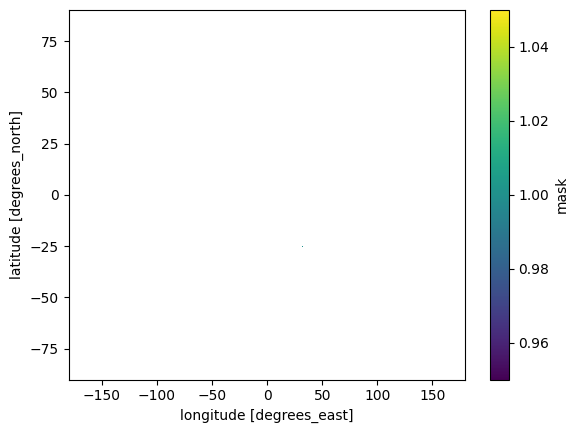

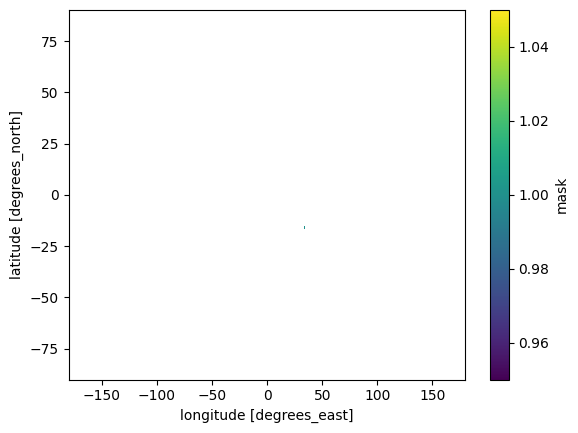

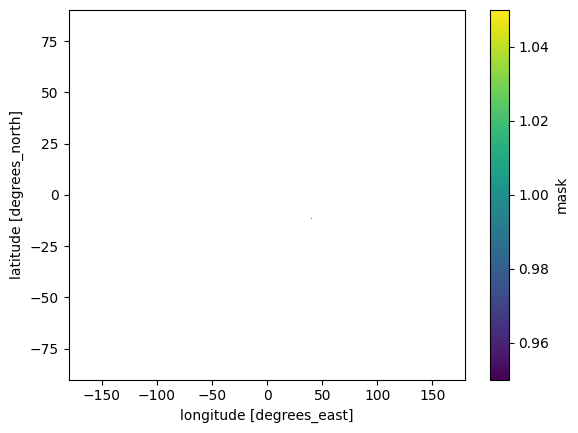

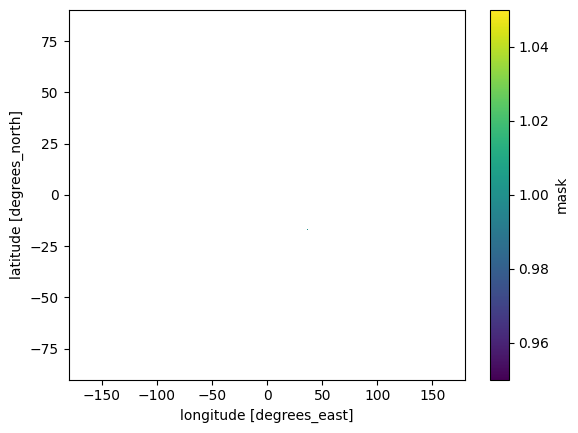

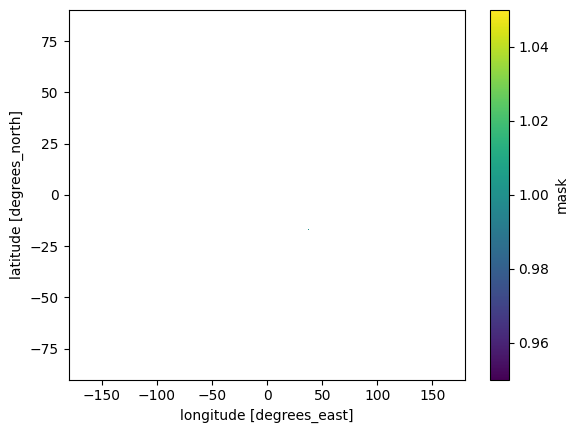

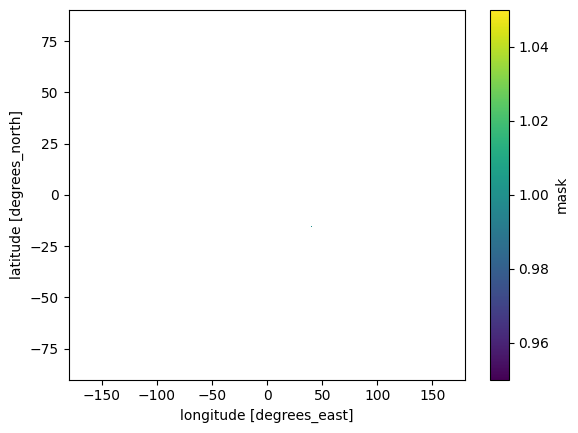

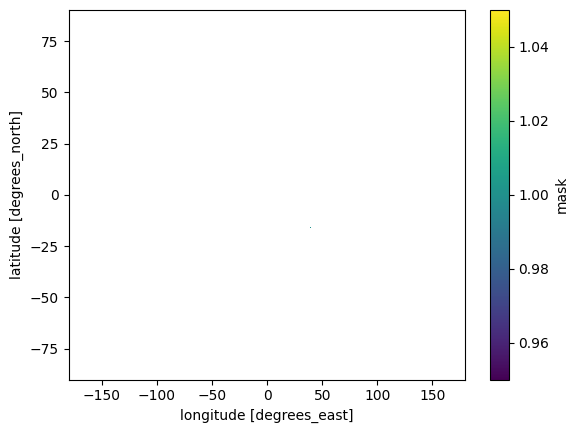

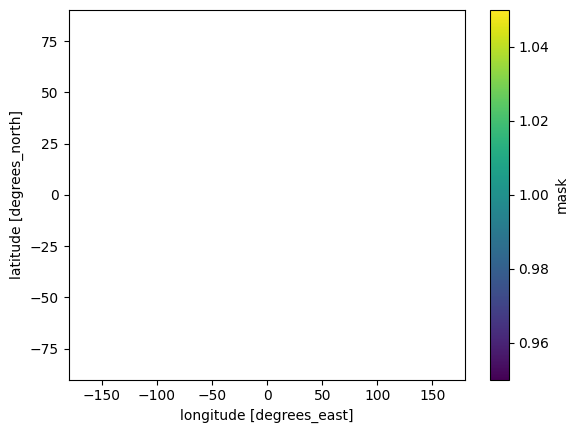

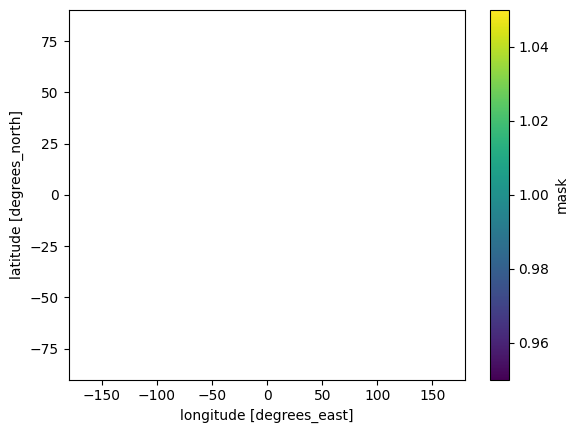

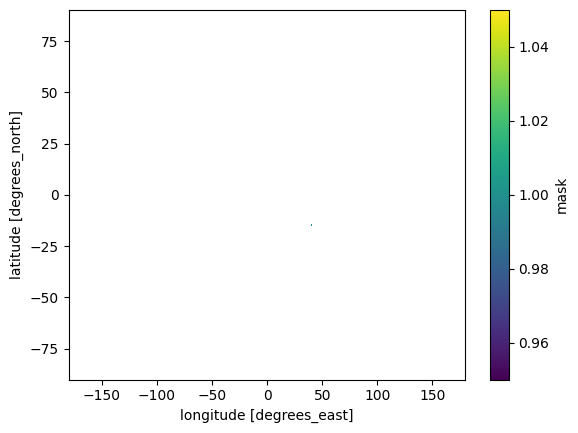

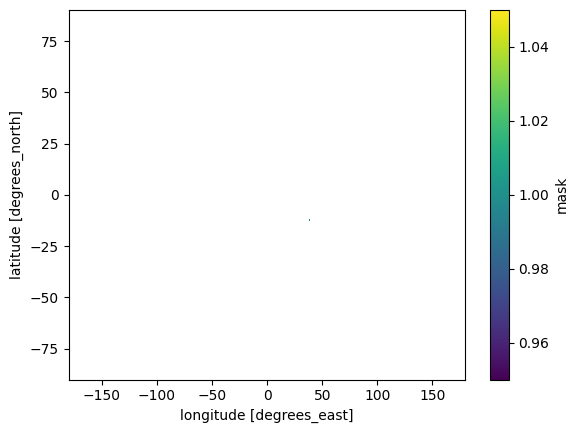

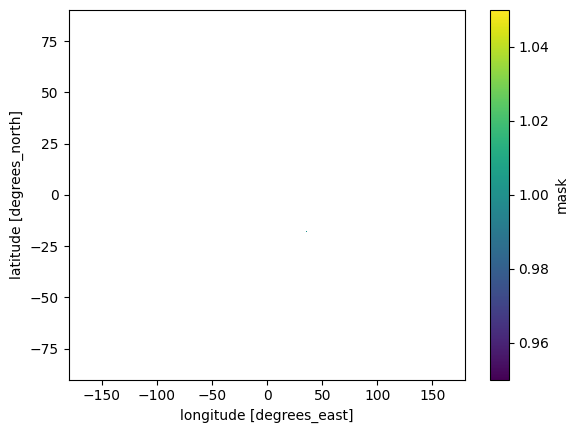

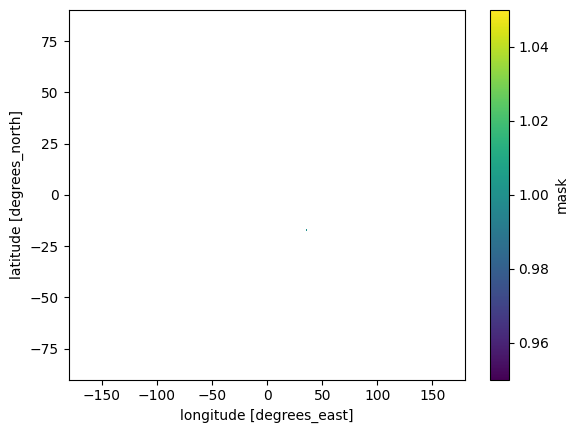

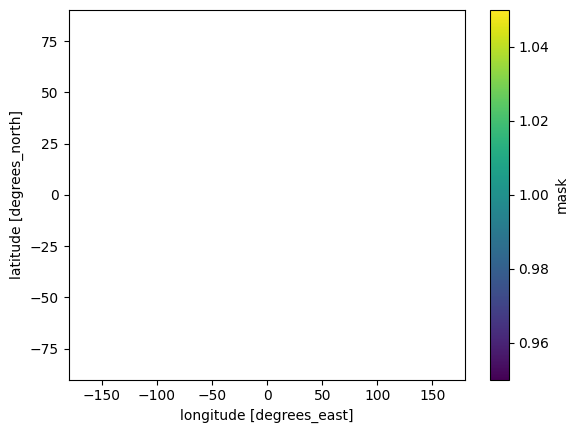

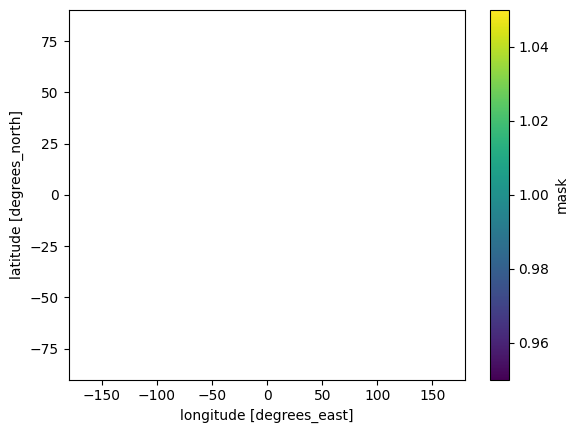

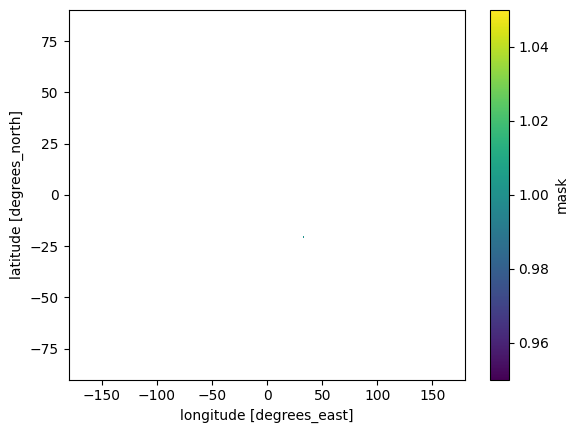

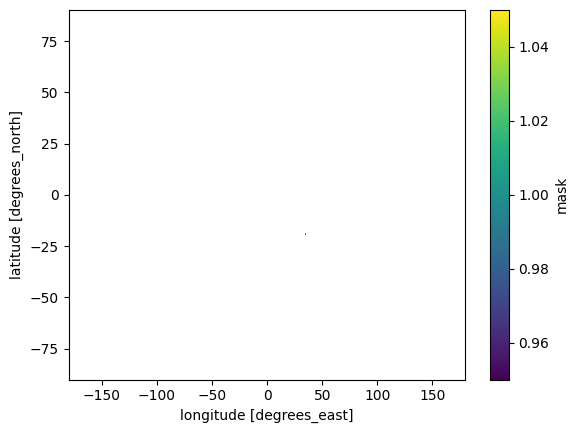

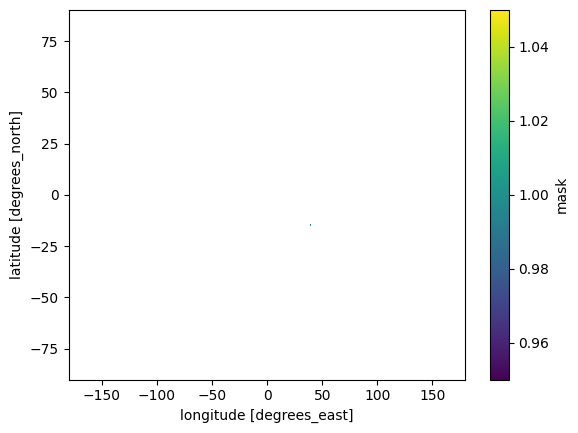

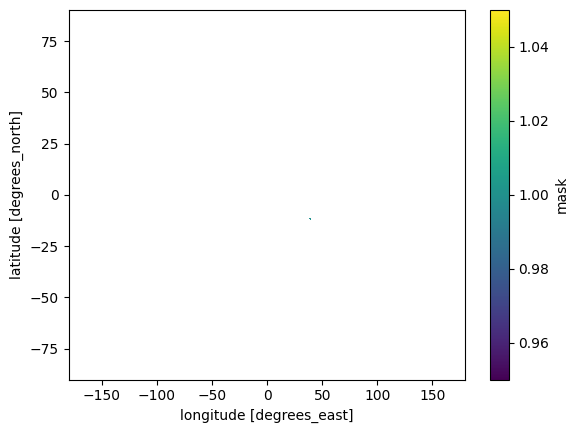

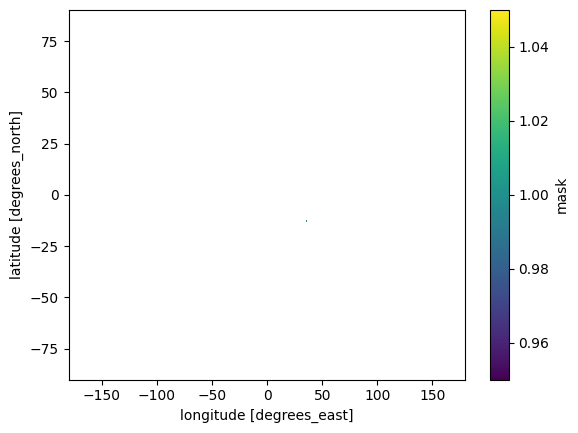

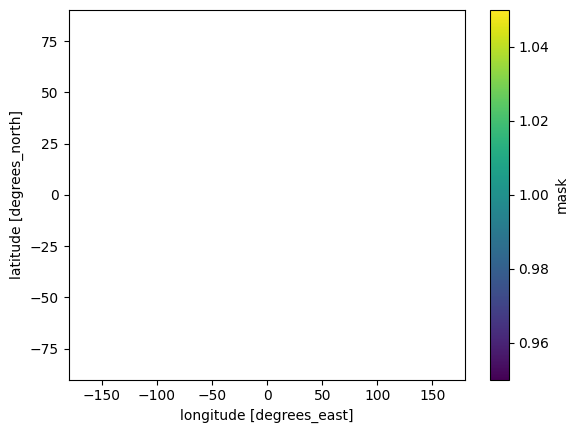

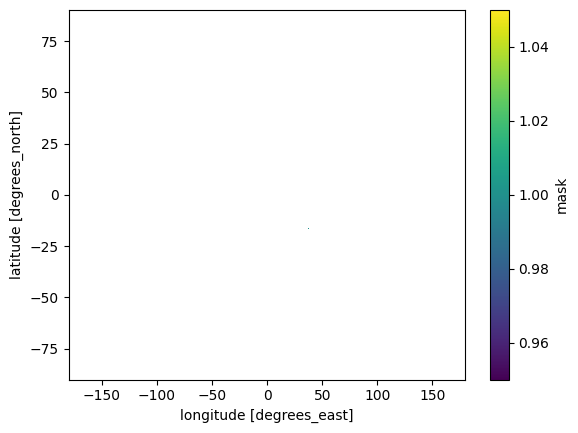

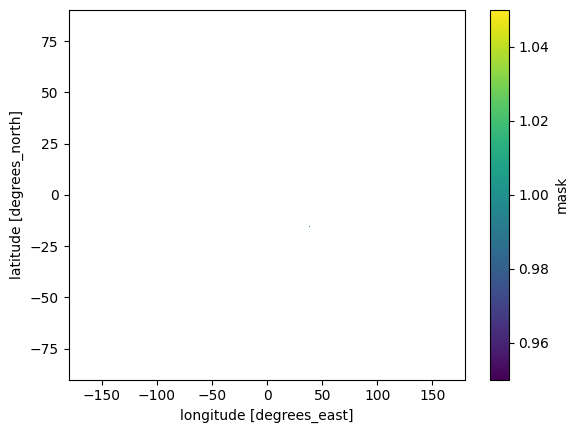

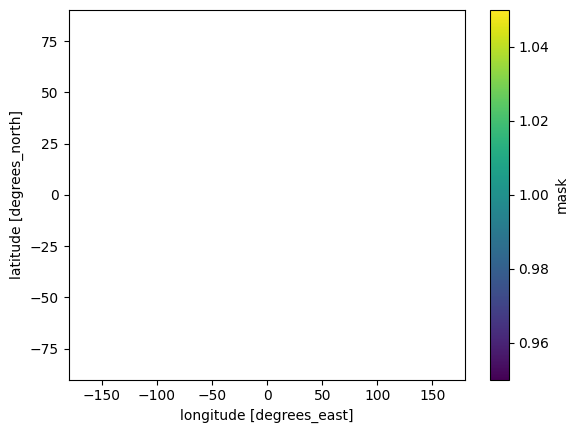

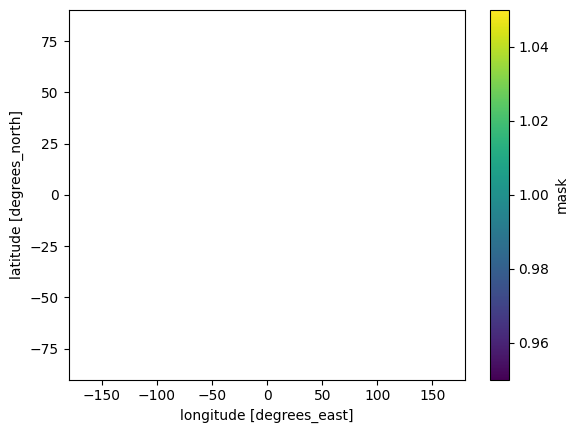

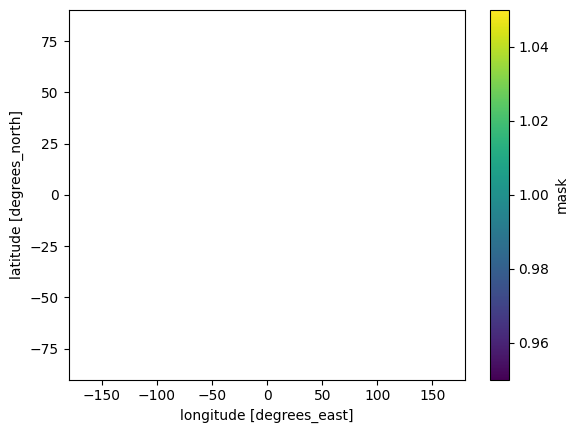

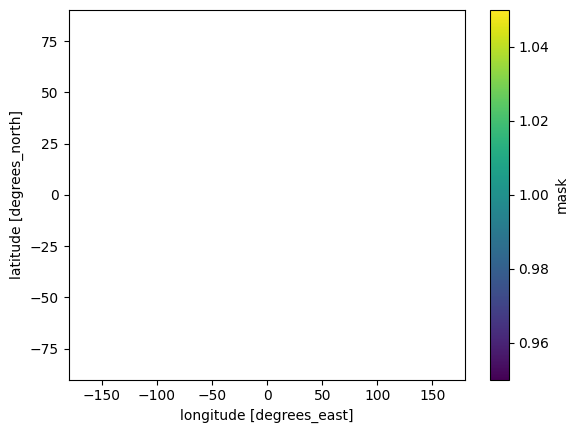

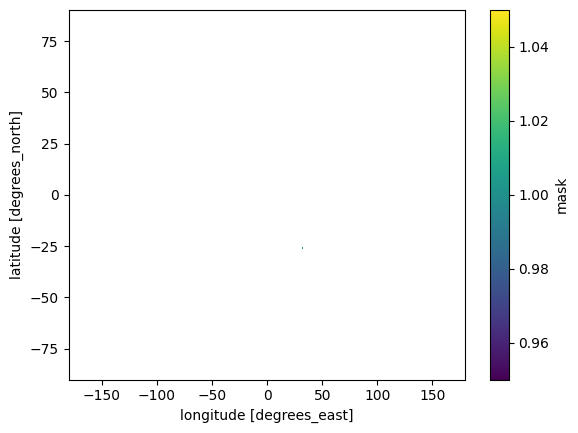

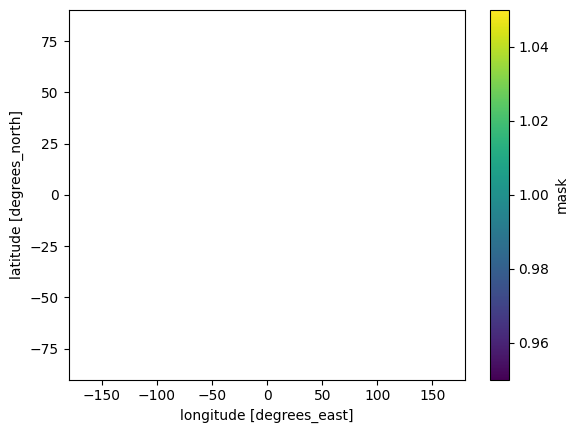

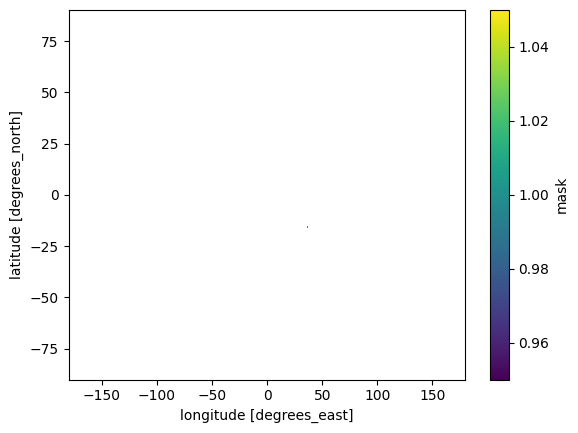

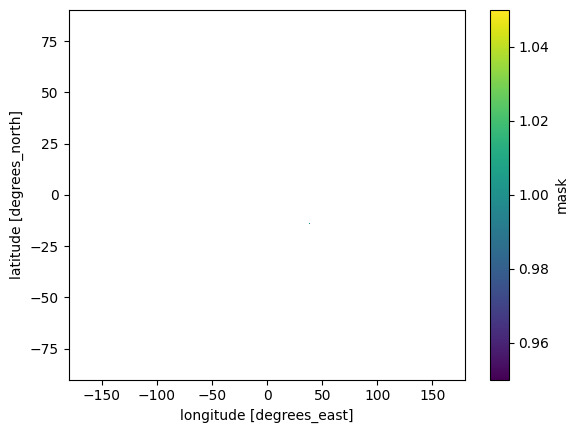

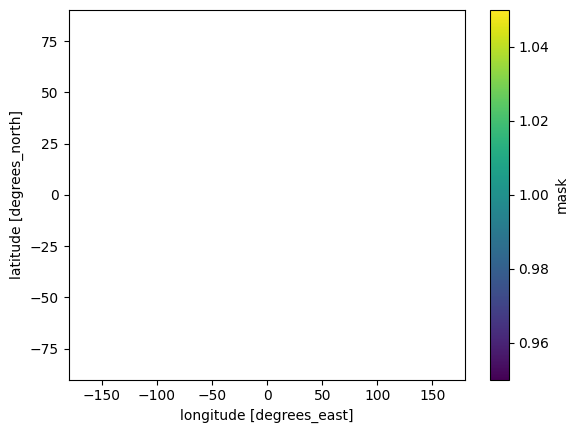

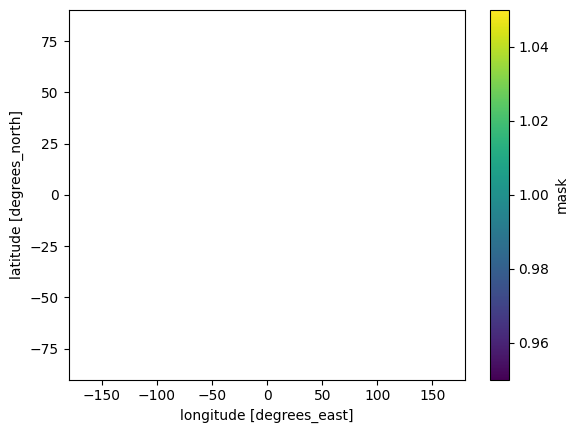

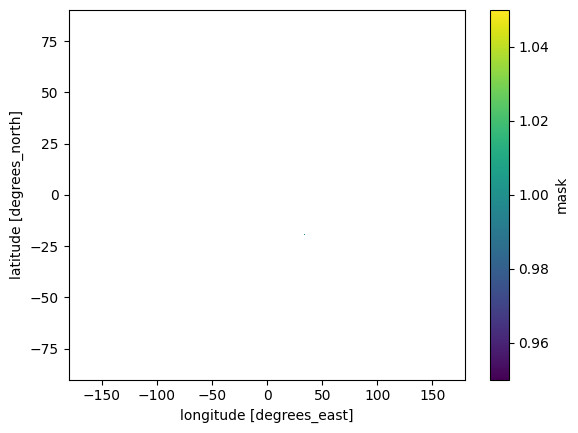

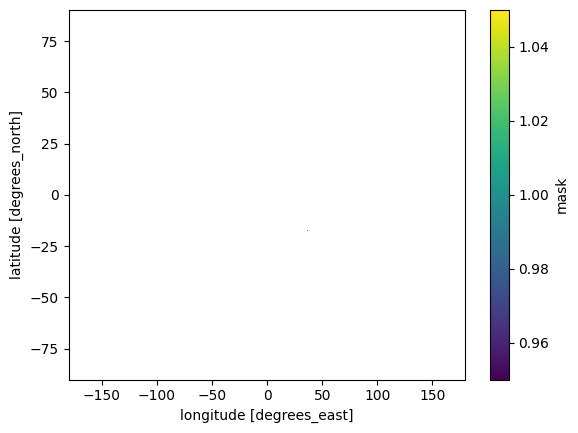

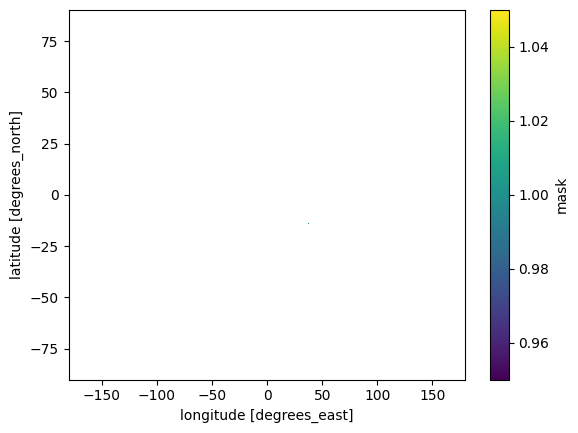

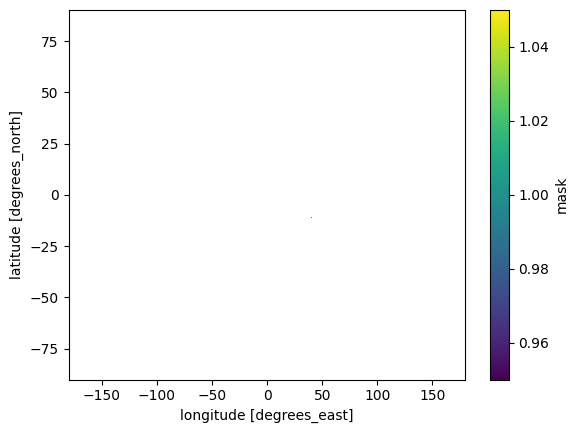

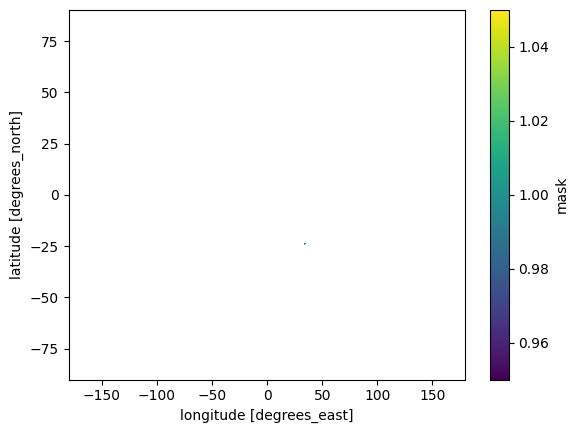

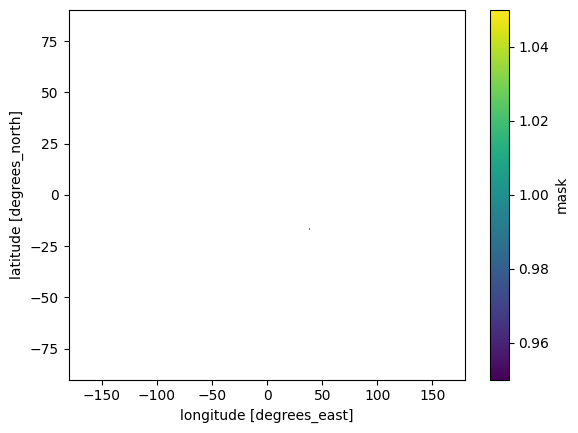

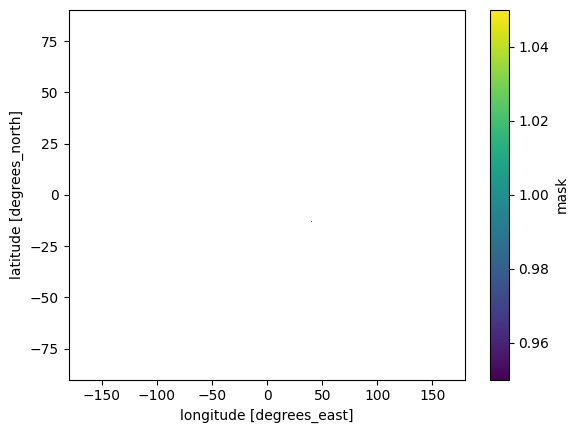

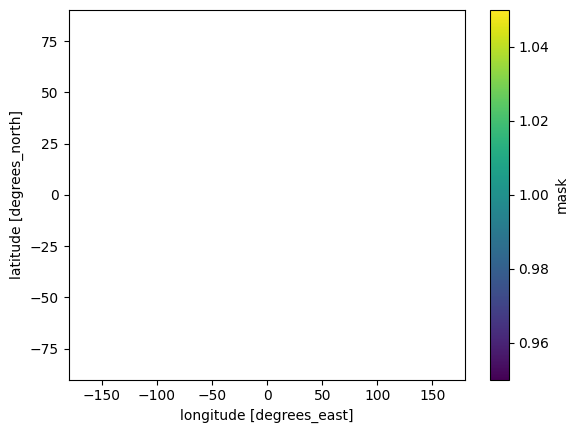

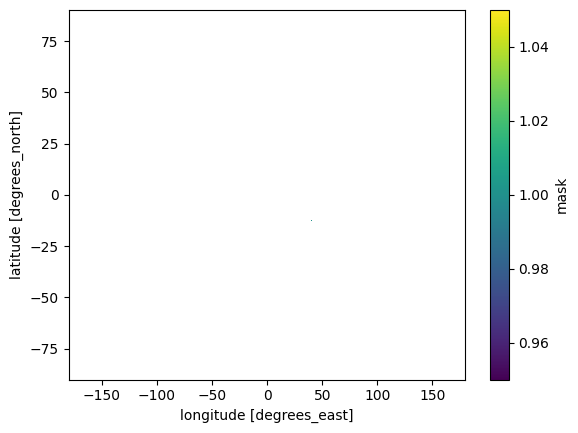

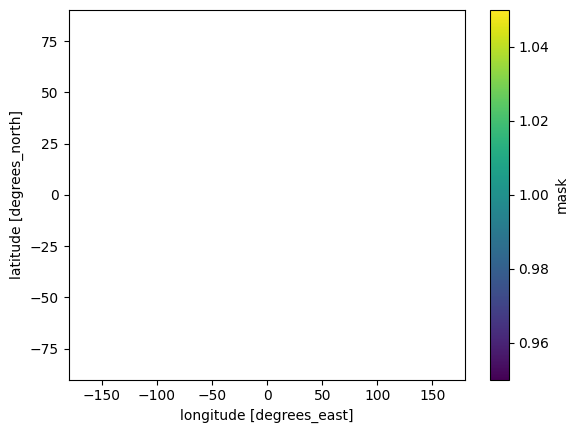

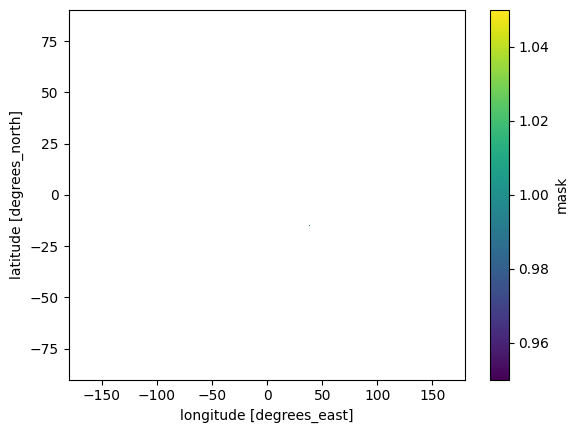

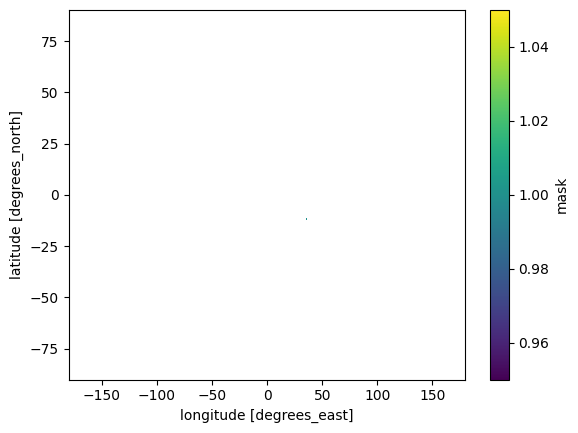

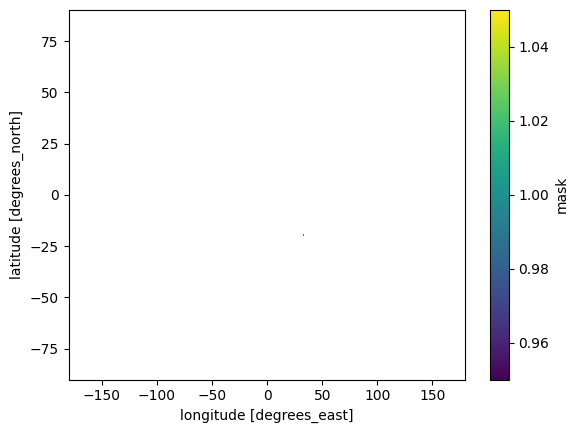

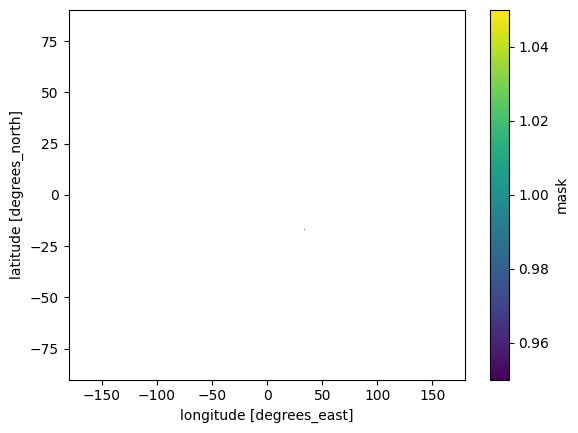

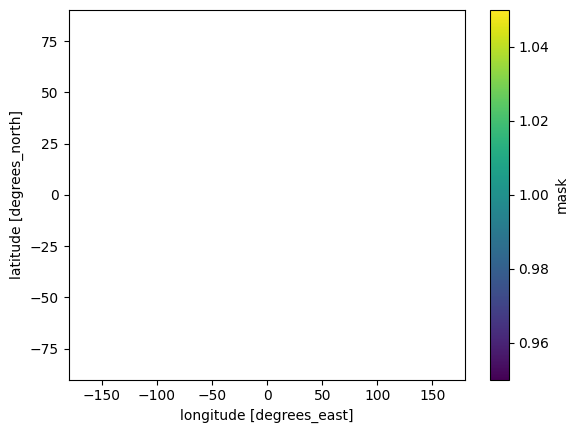

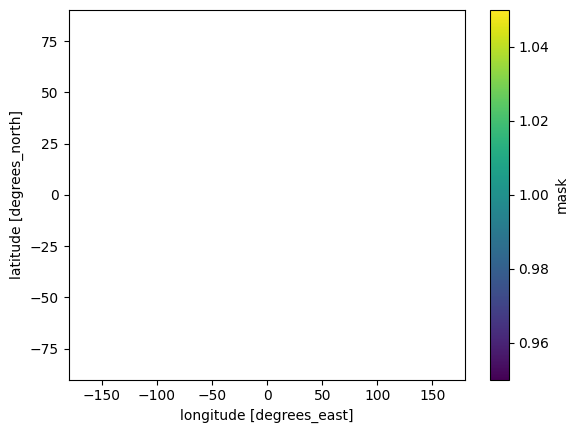

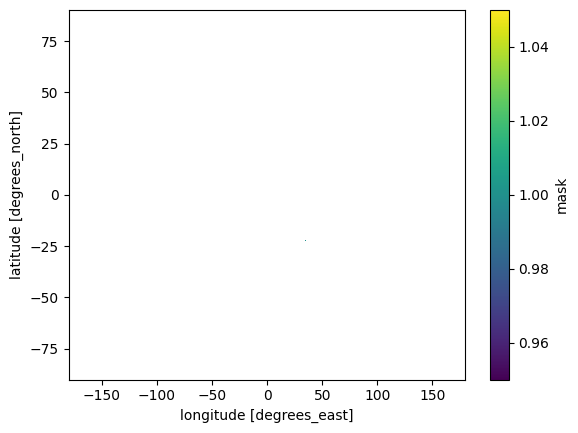

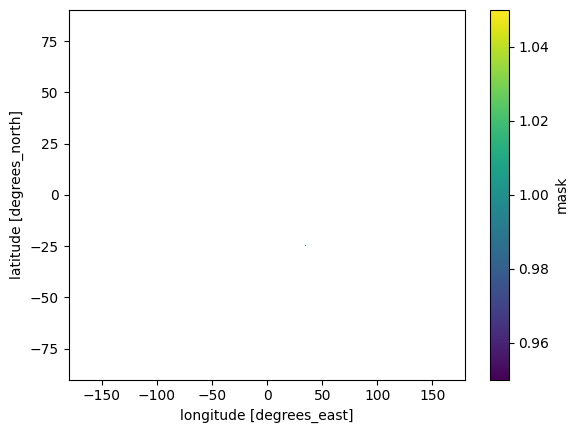

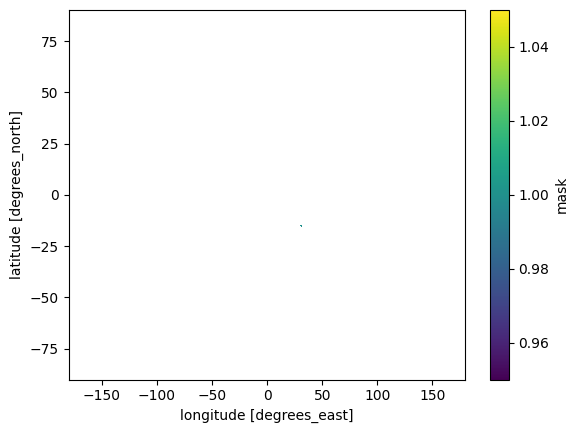

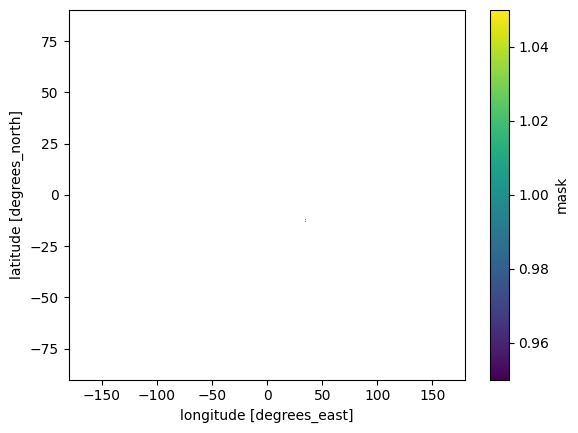

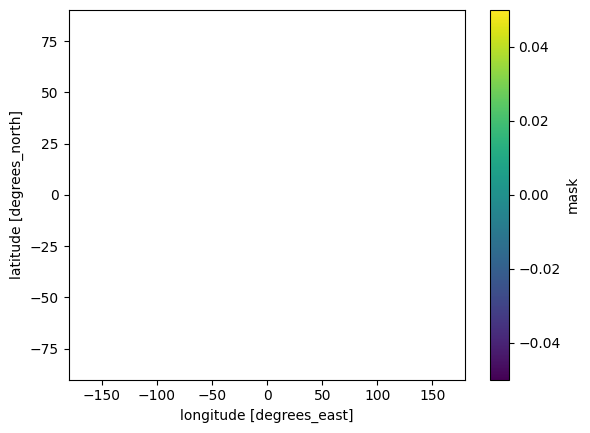

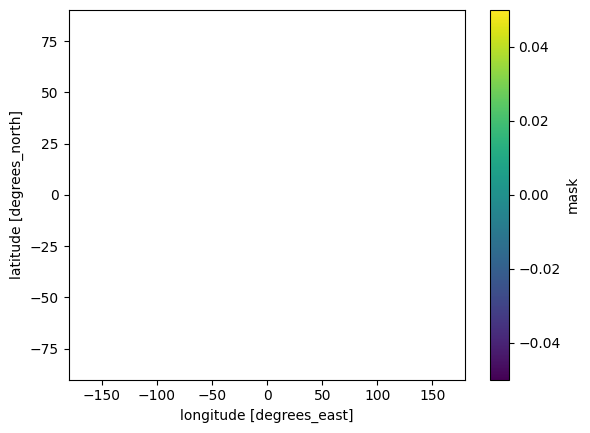

In [29]:
# Check all individual admin2 FNIDs
npoints = np.array([])

for ifnid in shapefile['FNID']:
    print(ifnid)
    fnshp = shapefile.loc[ (shapefile.FNID.isin([ifnid])), 'geometry' ]
    fnshp = fnshp.to_crs('epsg:4326')
    #plt.figure()
    #fnshp.plot()
    
    #print(fnshp.index.values) # this increases with the number of polygons in the original shapefile 
    adminmask = regionmask.mask_geopandas(fnshp, landmask_ecm.lon, landmask_ecm.lat)
    adminmask = xr.where(adminmask == fnshp.index.values, 1, np.nan) # otherwise this increases and the mask has values 0-len(fnids)
    #print(adminmask.shape)

    if int(adminmask.sum().values) != 0:
        #iregion = regionmask.Regions([fnshp]) # not working
        #adminmask_frac = iregion.mask_3D_frac_approx(landmask_ecm)
        #adminmask_frac.plot()
        
        # calculate area in drought
        indicator="SPI"
        aid_spi_ecm = {}
        #for window in [1,3,6,12,24,36,48]:
        for window in [1]:
            
            print(f"Processing SPI-{window}")
            swindow=f"w{window}"
            aid_spi_ecm = {}
            #aid_spi_ecm[swindow] = {}
            
            for severity in severity_list:    
                ivar = f"{indicator}{window}_{severity}"
                aid_spi_ecm[ivar] = pd.Series()
            for iquant in quant_list:    
                ivar = f"{indicator}{window}_{iquant}"
                aid_spi_ecm[ivar] = pd.Series()
        
            date_list_ecm = []
            #for iyyyy in range(syyyy, eyyyy+1):
            for iyyyy in range(1991, 1991+1):
                for imonth in range(1,13):
        
                    idate = f"{iyyyy}-{str(imonth).zfill(2)}"
                    date_list_ecm.append(f"{iyyyy}-{str(imonth).zfill(2)}")
                    
                    ifile   = os.path.join(f"{ipath_ecmwf}/{indicator.lower()}/{indicator.lower()}{window}", f"{indicator}{window}_gamma_global_era5_moda_ref1991to2020_{iyyyy}{str(imonth).zfill(2)}.nc")    
                    spi_ecm = xr.open_dataset(ifile)[f'{indicator}{window}']    
                    spi_ecm = xr.where(spi_ecm == -9999, np.nan, spi_ecm).isel(time=0)
        
                    for severity in severity_list:

        
                        if severity == "mild":
                            thresh_min = -1
                            thresh_max = 0
                        if severity == "moderate":
                            thresh_min = -1.5
                            thresh_max = -1
                        if severity == "severe":
                            thresh_min = -2
                            thresh_max = -1.5
                        if severity == "extreme":
                            thresh_min = -999
                            thresh_max = -2
                        if severity == "any":
                            thresh_min = -999
                            thresh_max = -1
        
                        # calculate area in drought
                        rspi   = spi_ecm.copy()*adminmask
                        dmask  = xr.where((rspi > thresh_min) & (rspi <= thresh_max), 1, np.nan)
                        #plt.figure()
                        #dmask.plot()
                        tmp    = 100 * (dmask*area_2d_adj_ecm).sum(dim=["lat", "lon"]) / (adminmask*area_2d_adj_ecm).sum(dim=["lat", "lon"])
                        #print(tmp[0])
    
                        ivar = f"{indicator}{window}_{severity}"
                        aid_spi_ecm[ivar] = pd.concat([aid_spi_ecm[ivar], pd.Series({'aid': tmp.values[0]})], ignore_index=True)

                    
                    for iquant in quant_list:
                        
                        rspi   = spi_ecm.copy()*adminmask
                        if iquant == "min":
                            tmp = rspi.min()
                        if iquant == "median":
                            tmp = rspi.median()
                        if iquant == "max":
                            tmp = rspi.max()
                        print(rspi.min().values)
                        print(rspi.median().values)
                        print(rspi.max().values)
                        ivar = f"{indicator}{window}_{iquant}"
                        aid_spi_ecm[ivar] = pd.concat([aid_spi_ecm[ivar], pd.Series({'aid': tmp.values})], ignore_index=True)



            #print(aid_spi_ecm)
    
            # write to dataframe to write to csv
            dfdata = pd.DataFrame(aid_spi_ecm)
            dfdata.index = pd.to_datetime(date_list_ecm).strftime('%Y%m%d')
            dfdata.index.name = "YYYYMMDD"
            #print(dfdata)
        
            start_index = pd.to_datetime(date_list_ecm[0]).strftime('%Y%m%d')
            end_index   = pd.to_datetime(date_list_ecm[-1]).strftime('%Y%m%d')
            save_name = f"MOZ_WFS_0001_{indicator}{window}_{start_index}_{end_index}_AID_{ifnid}.csv"
            #save_path = os.path.join(tif_dir,save_name)
            print(save_name)

    # Check number of pixels in adminmask
    print(int(adminmask.sum().values))
    npoints = np.append(npoints,int(adminmask.sum().values))

    # Test plot
    plt.figure()
    adminmask.plot()

# all admin2 FNIDs together
#fnshpa = shapefile.loc[ (shapefile.FNID.isin(shapefile['FNID'])), 'geometry' ] 
#fnshpa.plot()

In [11]:
print(npoints)

[ 8.  1.  7.  3.  4.  7.  8.  2.  0.  9. 11.  5.  9.  5.  9. 10.  8. 15.
 11. 22.  5.  7. 11.  5.  3.  2.  1.  0.  0.  1.  1.  0.  0.  0.  0.  0.
  6.  7.  4.  2.  7. 19. 13.  3.  9.  5.  6. 10.  7.  3.  0.  4.  0.  4.
  9.  1.  1.  9.  6.  3.  7.  2.  3.  2. 10. 13. 20. 11.  3.  8. 19.  6.
 13.  3. 13. 10. 12.  9.  6.  3.  3.  4. 10.  3. 22. 10.  0.  8. 26. 11.
 11.  8.  8. 11. 12.  0.  7.  7. 10.  2. 21.  7.  6.  5.  7.  5. 12.  4.
 11.  6.  3.  6.  6.  6.  4. 24.  9. 10.  4.  5.  7. 11.  5. 16.  8.  3.
  4.  5.  4.  1.  2.  4.  4.  3.  4.  9.  4.  5.  6.  4.  7.  3. 11. 13.
  3.  1.  1.  3.  9. 18.  9.  5.  5.  6.  8.  3. 16.  8.  0.  0.]
